


<h5 style="color:#1f7123;">How to run</h5>
Please look over README.md before continuing.

1. If you want to Run All:

    Extract all files from 'WMeter5K' into directory of this notebook so
    its (notebook directory) \ WMeter5K\WMeter5k\images


Note on disk usage: If you choose to extract all theres 5000 meter images, 
cropping step writes 27k+ cropped images, so just keep in mind it takes a 
minute to delete it all once you're done!

<h3 style="color:#1f77b4;">Project Overview</h3>

This notebook performs image classification using the <strong>WMeter5K</strong> water meter dataset.

The task is to classify cropped water meter dial images into <strong style="color:#9467bd;">30 dial-position classes</strong>. 
Each class combines a digit 0 to 9 with a pointer sub-sector: start, middle or end.

Dataset: WMeter5K, from Zhang et al. (2025).

Source: https://github.com/ZZZHANG-jx/WMeter-Reader/tree/master


<h4 style="color:#1f77b4;">Table of Contents</h4>
<ul>
    <li><a href="#Imports">Imports</a></li>
    <li><a href="#Data-explore">Data Exploration</a>
        <ul>
            <li><a href="#Inspect-Images">Inspect Images</a></li>
        </ul>
    </li>
    <li><a href="#Preprocessing">Preprocessing</a>
        <ul>
            <li><a href="#Class-Labels">Class Labels</a></li>
            <li><a href="#Rotate-helpers">Rotation Helpers</a></li>
            <li><a href="#Dial-size-distrib">Dial Size Distribution</a></li>
            <li><a href="#Rotating-image">Image Centering</a></li>
            <li><a href="#Cropping-pipeline">Cropping Pipeline</a></li>
            <li><a href="#Class-distrib">Class Distribution</a></li>
            <li><a href="#Visualise-cropping">Check Cropped Images</a></li>
            <li><a href="#Data-attrition">Data Attrition</a></li>
            <li><a href="#Splitting">Train / Validation / Test Split</a></li>
            <li><a href="#Transforms-Augmentation">Transforms and Augmentation</a>
                <ul>
                    <li><a href="#Normalise-crops">Normalise Cropped Images</a></li>
                    <li><a href="#Check-Normalise-crops">Check Normalised Cropped Images</a></li>
                </ul>
            </li>
            <li><a href="#Dataset-class">Dataset Class</a></li>
            <li><a href="#Dataloaders">Dataloaders</a></li>
        </ul>
    </li>
    <li><a href="#Models">Model Architectures</a>
        <ul>
            <li><a href="#ResNet18">ResNet-18</a></li>
            <li><a href="#EffNetB0">EfficientNet-B0</a></li>
            <li><a href="#coord-att">Coordinate Attention</a></li>
            <li><a href="#effnet-coord-att">EfficientNet-B0 + CoordAtt</a></li>
            <li><a href="#Check-models">Check Models</a></li>
        </ul>
    </li>
    <li><a href="#Training">Training</a>
        <ul>
            <li><a href="#Train-help">Training Helpers</a></li>
            <li><a href="#hyper-params">Hyperparameters</a></li>
            <li><a href="#Train-resnet18">Train ResNet-18 (Benchmark)</a></li>
            <li><a href="#Train-effnet-ca">Train EfficientNet-B0 + CA (Chosen Method)</a></li>
            <li><a href="#Train-effnet-noca">Train EfficientNet-B0 without CA (Comparison)</a></li>
            <li><a href="#Train-curves">Training Curves</a></li>
        </ul>
    </li>
    <li><a href="#Evaluation">Evaluation</a>
        <ul>
            <li><a href="#Load-best">Load Best Checkpoints</a></li>
            <li><a href="#Test-metrics">Test-set Metrics</a></li>
            <li><a href="#McNemar">McNemar</a></li>
            <li><a href="#Confusion-matrices">Confusion Matrices</a></li>
            <li><a href="#Comp-table">Comparison Table</a></li>
            <li><a href="#Error-analysis">Error Analysis</a></li>
        </ul>
    </li>
</ul>

<a id="Imports"></a>
<h3 style="color:#1f77b4;">Imports</h3>

The following libraries contributed:


<strong>Data exploration</strong>
<ul>
    <li><code>os</code> handles the file and folder paths when reading images.</li>
    <li><code>random</code> picks random samples and shuffles data so runs stay repeatable seed.</li>
    <li><code>matplotlib</code> draws plots, image grids, training curves, and confusion matrix.</li>
</ul>

<strong>Preprocessing and cropping</strong>
<ul>
    <li><code>numpy</code> handles arrays for image data and metrics.</li>
    <li><code>pandas</code> builds small results tables like model comparison table.</li>
    <li><code>cv2</code> reads, converts, rotates, resizes, and saves dial images.</li>
    <li><code>math</code> does angle math for finding / rotating dial pointers.</li>
    <li><code>tqdm</code> sanity progress bars for long loops.</li>
</ul>

<strong>Dataset and transforms</strong>
<ul>
    <li><code>torch</code> deep learning library used to build and train models.</li>
    <li><code>transforms</code> converts cropped images into tensors and normalises.</li>
    <li><code>Image</code> opens image files and passes them to transforms.</li>
    <li><code>Dataset</code> and <code>DataLoader</code> wrap data so loads in batches for training.</li>
</ul>

<strong>Model building</strong>
<ul>
    <li><code>nn</code> holds building blocks for model layers such as conv, batch norm, and linear.</li>
    <li><code>F</code> provides functions like activations and pooling for models.</li>
</ul>

<strong>Training</strong>
<ul>
    <li><code>time</code> measures how long each model takes to train.</li>
    <li><code>csv</code> writes training logs to CSV.</li>
    <li><code>optim</code> optimiser (SGD) updates model weights.</li>
</ul>

<strong>Evaluation</strong>
<ul>
    <li><code>mcnemar_table</code> and <code>mcnemar</code> run McNemars test to check if accuracy differences are real.</li>
</ul>

In [111]:
# Data exploration
import os
import random
import matplotlib.pyplot as plt

# Preprocessing and cropping
import numpy as np
import pandas as pd
import cv2
from math import atan2, degrees, radians, sin, cos
from tqdm import tqdm

# Dataset and transforms
import torch
from torchvision import transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Model building
import torch.nn as nn
import torch.nn.functional as F

# Training
import time
import csv
import torch.optim as optim

# Evaluation
from mlxtend.evaluate import mcnemar_table, mcnemar

<a id="Data-explore"></a>
<h3 style="color:#1f77b4;">Data Exploration</h3>
<a id="Inspect-Images"></a>
<h5 style="color:#1fb4a7;">Inspect Images</h5>

In [ ]:
# --- File inputs and outputs ---
base_dir         = os.path.join("WMeter5K", "WMeter5K")
image_dir        = os.path.join(base_dir, "images")
image_dir = os.path.join(base_dir, "images")
pointers_out_dir = os.path.join(base_dir, "pointers_A2")

# WMeter5K dataset creators own provided label.txt file
# https://github.com/ZZZHANG-jx/WMeter-Reader/tree/master
# https://1drv.ms/f/s!Ak15mSdV3Wy4ibBVkrDerbSXLaEH7Q?e=RUzERx
label_file = os.path.join(base_dir, "label.txt")

Total source images: 5000


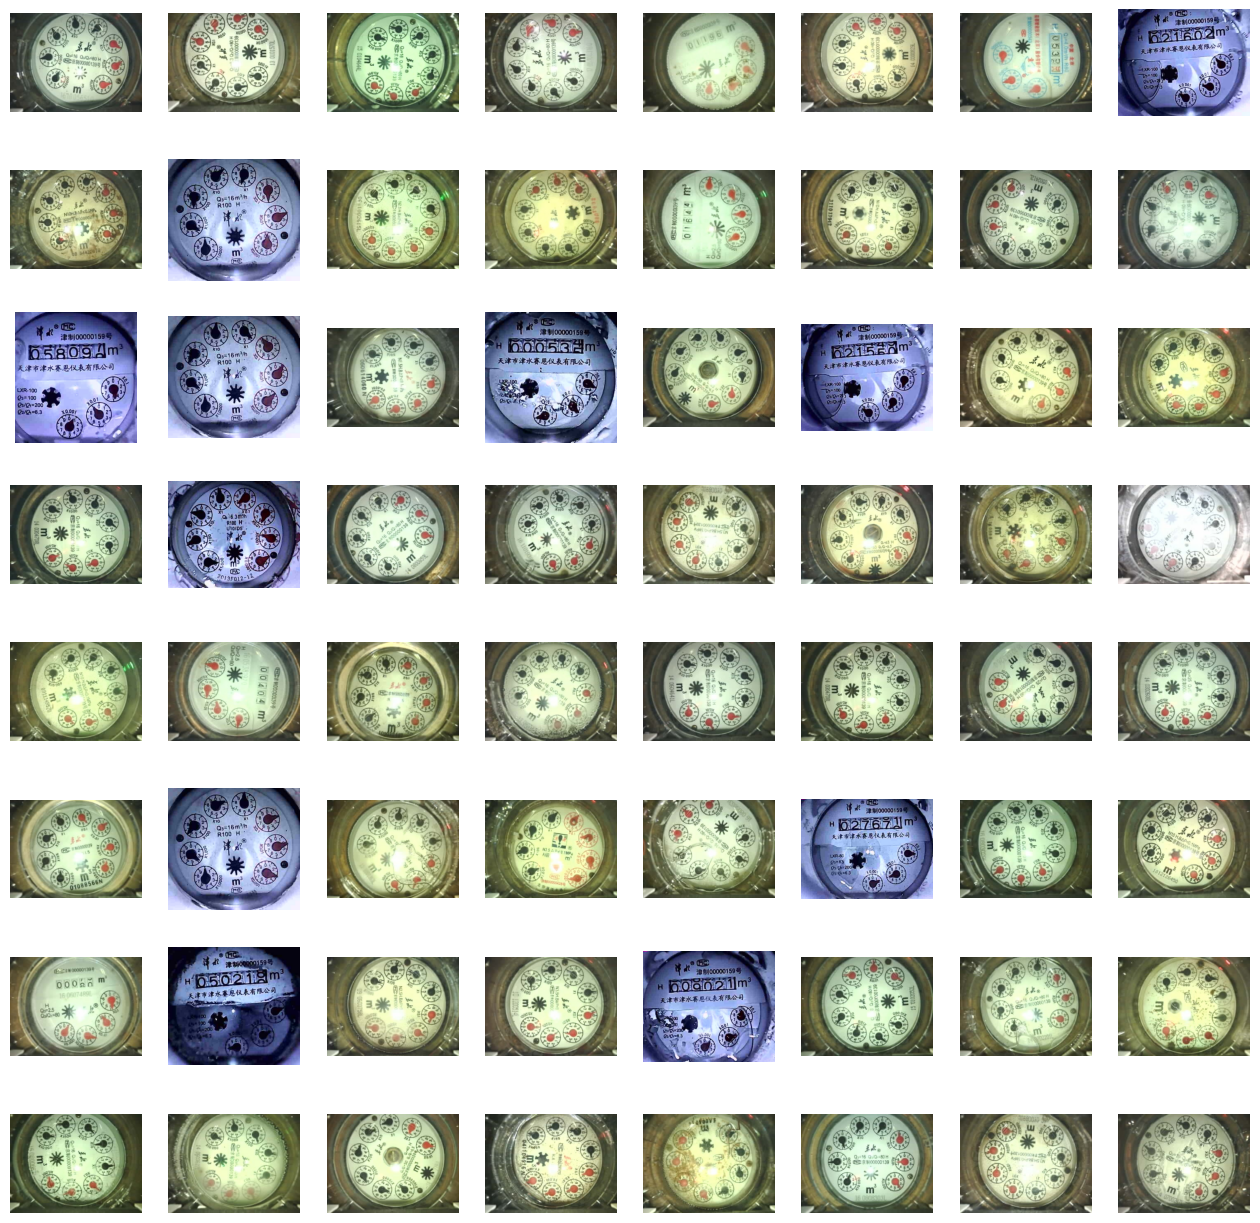

In [113]:
image_files = []

for file in os.listdir(image_dir):
    if file.endswith(".jpg"):
        image_files.append(os.path.join(image_dir, file))

print("Total source images:", len(image_files))

random.seed(42)
sample_images = random.sample(image_files, min(64, len(image_files)))

plt.figure(figsize=(16, 16))

for i, path in enumerate(sample_images):
    img = plt.imread(path)

    plt.subplot(8, 8, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.show()

<a id="Preprocessing"></a>
<h3 style="color:#1f77b4;">Preprocessing</h3>
<a id="Class Labels"></a>
<h5 style="color:#1fb4a7;">Class Labels</h5>

The WMeter5K label.txt encode pointer positions with 30 dial classes:
10 digits 0-9 combined with 3 sub-sectors per dial based on angle.

- `5 `    - pointer in the middle third of the 5 sector
- `5-`    - pointer at start of 5, near 4, but still in the 5 sector
- `5+`    - pointer at end of 5, near 6, but still in the 5 sector

In [114]:
class_labels = [
    "0", "1", "2", "3", "4", "5", "6", "7", "8", "9",
    "0-", "1-", "2-", "3-", "4-", "5-", "6-", "7-", "8-", "9-",
    "0+", "1+", "2+", "3+", "4+", "5+", "6+", "7+", "8+", "9+"
]

<a id="Rotate-helpers"></a>
<h5 style="color:#1fb4a7;">Rotation Helpers</h5>

These helper functions prepare each annotation line before cropping:

- `parse_label_line()` splits each label-file row into the image name, pointer, and meter reading.
- `parse_pointer()` splits one pointer into 8 coord values and its dial class label.
- `fit_coords()` keeps the pointer coords inside the image boundaries so cropping does not go outside the image.

In [115]:
def parse_label_line(line):
    """Split one label-file row into image name, pointer data, and meter reading."""

    # Split line into three parts
    im_name, pointers_line, meter_read = line.split('\t')

    # Clean meter_read of \n and full stops
    meter_read = meter_read.replace('\n', '').replace('.', '')

    # Split all pointer annotations for this image into separate entries
    # for parse_pointer
    pointers_str = pointers_line.replace('\n', '').split(';')

    return im_name, pointers_str, meter_read


def parse_pointer(pointer_str):
    """Split one pointer entry into coordinates and label."""

    # Split coordinates from the class label
    coord, predict = pointer_str.split('/')

    # Take the coordinate text, split on commas, and turn each 
    # coordinate into an integer so easier to use in 
    # cropping/calculations.
    coords = [int(c) for c in coord.split(',')]

    return coords, predict


def fit_coords(coords, w, h):
    """
    Keep the pointer box inside the image.

    Some pointer boxes may have corners outside the image. This moves
    any outside back to nearest image edge so wont error. Got general
    idea from https://en.wikipedia.org/wiki/Clamp_(function)
    (Arguably overkill)
    """

    out = []

    # Check each x and y coordinate
    for i, v in enumerate(coords):

        # Even positions = x values, odd positions = y values
        limit = w if i % 2 == 0 else h

        # Lock the value between 0 and the image limit
        out.append(min(max(v, 0), limit))

    return out

<a id="Dial-size-distrib"></a>
<h5 style="color:#1fb4a7;">Dial Size Distribution</h5>



count    35782.000000
mean        52.142462
std         27.103209
min         27.586228
25%         43.046487
50%         44.339576
75%         46.389654
max        251.097591
dtype: float64

Median width: 43.4 px
Median height: 44.0 px

 32 px: 99.9% downsampled
 64 px: 13.4% downsampled
 96 px: 1.7% downsampled
128 px: 1.7% downsampled
160 px: 1.6% downsampled
224 px: 1.6% downsampled


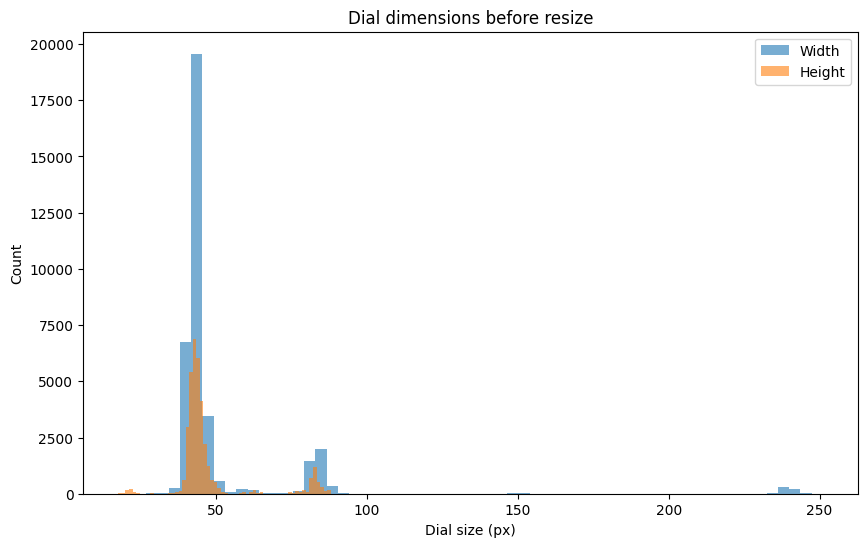

In [116]:
# Measure every future dial crop in the label file to find distribution of
# cropped dial sizes to justify choosing dial cropped iamge size for CNN input
widths = []
heights = []

with open(label_file) as f:
    lines = [ln for ln in f.readlines() if ln.strip()]

# Iterate over the dial coords in each line of label.txt
for line in lines:
    im_name, pointers, gt = parse_label_line(line)

    for pointer in pointers:
        # This now measures edges to get widths and heights of the dial
        # thats each row in label.txt
        parsed = parse_pointer(pointer)

        coords, predict = parsed

        x0, y0, x1, y1, x2, y2, x3, y3 = coords

        # Dials sit at angles, so each edge is a diagonal between two corners
        # Pythagoras (dx, dy as the two short sides) gives that diagonal.

        # Horizontal and vertical gap between the two corners of the top edge
        dx = x1 - x0
        dy = y1 - y0
        # Straight line length of that edge (pythagoras) = dial width
        w = (dx**2 + dy**2) ** 0.5

        # Horizontal and vertical gap between the two corners of the side edge
        dx = x3 - x0
        dy = y3 - y0
        # Straight line length of that edge (pythagoras) = dial height
        h = (dx**2 + dy**2) ** 0.5

        widths.append(w)
        heights.append(h)

widths = np.array(widths)
heights = np.array(heights)
longer = np.maximum(widths, heights)

# Summary stats
print(pd.Series(longer).describe())
print()


# Typical dial width and height in pixels 
# (using median as seems logical considering summary stats outliers)
print("Median width:", round(np.median(widths), 1), "px")
print("Median height:", round(np.median(heights), 1), "px")
print()

# Compare possible model input sizes 
# (must be multiples of 32 due to both models architectures)
for size in [32, 64, 96, 128, 160, 224]:
    # percent of dials losing detail
    downsampled = (longer > size).mean() * 100
    print(f"{size:3} px: {downsampled:.1f}% downsampled")

plt.figure(figsize=(10, 6))
plt.hist(widths, bins=60, alpha=0.6, label="Width")
plt.hist(heights, bins=60, alpha=0.6, label="Height")
plt.xlabel("Dial size (px)")
plt.ylabel("Count")
plt.legend()
plt.title("Dial dimensions before resize")
plt.show()

<a id="Rotating-image"></a>
<h5 style="color:#1fb4a7;">Image Centering</h5>

The rotate() function, adapted from Zhang et al. (2025), rotates each 
pointer crop so the surrounding box is center. It expands the image with 
a white background so the corners are not cut off, then crops the rotated 
pointer using the new bounding box.

Each pointer crop is then resized to 96x96 for use with EfficientNet.

In [117]:
def rotate(img, pt1, pt2, pt3, pt4):
    """
    Adapted from Zhang et al 2025 WMeter-Reader cropping.py script:
    https://github.com/ZZZHANG-jx/WMeter-Reader/blob/master/demo/cropping.py

    Straightens the pointer area using its four corner points, then crops it.
    pt1 and pt4 are the two ends of the top edge (the edge rotated
    so it becomes horizontal). pt2 and pt3 are the other two corners.

    Changes I made:
        - This version uses atan2 for the rotation angle
        - Crops using all four rotated corner points
            Take all four rotated points, then use the minimum and 
            maximum x and y values.
        - Safety check at end
    """

    # Find the angle of the top edge (pt1 to pt4).
    change_x = pt4[0] - pt1[0]
    change_y = pt4[1] - pt1[1]
    angle = degrees(atan2(change_y, change_x))

    # Build a rotation matrix that rotates around the middle of the image.
    height = img.shape[0]
    width = img.shape[1]
    center = (width / 2, height / 2)
    rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)

    # Figure out how big output canvas needs to be so the rotated
    # image corners dont get cut off
    cos_a = abs(cos(radians(angle)))
    sin_a = abs(sin(radians(angle)))
    new_width = int(width * cos_a + height * sin_a)
    new_height = int(width * sin_a + height * cos_a)

    # Adjust the rotation matrix so its centered but centered inside
    # the greater output image
    rotation_matrix[0, 2] += (new_width - width)  / 2
    rotation_matrix[1, 2] += (new_height - height) / 2

    # Perform rotation. Warpaffine takes a pixel grid and changes it
    rotated_img = cv2.warpAffine(
        img,
        rotation_matrix,
        (new_width, new_height),
        borderValue=(255, 255, 255),
    )

    # Now also rotate the original points so that we know where the
    # new image is and can crop it
    def rotate_point(pt):
        x, y = pt[0], pt[1]
        new_x = rotation_matrix[0, 0] * x + rotation_matrix[0, 1] * y + rotation_matrix[0, 2]
        new_y = rotation_matrix[1, 0] * x + rotation_matrix[1, 1] * y + rotation_matrix[1, 2]
        return (new_x, new_y)

    p1 = rotate_point(pt1)
    p2 = rotate_point(pt2)
    p3 = rotate_point(pt3)
    p4 = rotate_point(pt4)

    # Find the smallest and largest x and y values
    # across all four rotated points for crop box
    xs = [p1[0], p2[0], p3[0], p4[0]]
    ys = [p1[1], p2[1], p3[1], p4[1]]

    left = int(min(xs))
    right = int(max(xs))
    top = int(min(ys))
    bottom = int(max(ys))

    # Crop the rotated image and return it.
    cropped = rotated_img[top:bottom, left:right]

    # Safety check
    if cropped.size == 0:
        return None
    return cropped

<a id="Cropping-pipeline"></a>
<h5 style="color:#1fb4a7;">Cropping Pipeline</h5>

Reads `label.txt`, shuffles lines and splits into train/val/test
at the meter level before any cropping. This keeps every dial from one 
meter image in the same split rather than mixing crops from the same 
meter across splits (prevents data leakage).

1. Loads image
2. For each dial:
   - Keep only 30 dial classes 
      (filter out digit rotor-dial sections on some meters that 
      combine dials and rotors)
   - Rotate and center image
   - Crop using the four-corner box
   - Resize to 96x96
   - Save file
3. Crops are written to folders (`train/`, `val/`, `test/`). 
The filename stores the class label for later.

Filename format: 
`crop_<label_file_name>_<image_file_name>_<line>_<i>_<label>.jpg`

Test mode processes only the first `test_image_limit` lines, for 
quick iteration.

NOTE: This is building on Zhang et al. (2025) cropping.py file, 
   things i have added/changed:
   - Data attrition tracking
   - Test mode for small batch testing of dial crop creation and model training.
   - No leaking meters dials into seperate splits
   - Import os usage for paths



In [118]:
# --- Test controls ---
test_mode = False
test_image_limit = 100
output_size = 96


# Store skipped examples for checking later
drop_examples = {
    "image not loaded": [],
    "pointer not parsed": [],
    "label not used": [],
    "save failed": [],
}


# Read label.txt and do image-level split BEFORE cropping
# This keeps all pointers from one meter in the same split
with open(label_file) as f:
    lines = [ln for ln in f.readlines() if ln.strip()]

random.seed(42)
random.shuffle(lines)

n = len(lines)
n_train = int(0.80 * n)
n_val = int(0.10 * n)

splits = {
    "train": lines[:n_train],
    "val": lines[n_train:n_train + n_val],
    "test": lines[n_train + n_val:],
}

# Quick sanity check
print({k: len(v) for k, v in splits.items()})



# --- Create cropped dial images ---

os.makedirs(pointers_out_dir, exist_ok=True)

image_dims = []

total_saved = 0
total_skipped = 0

# Iterate over folders
for split_name, split_lines in splits.items():
    out_dir = os.path.join(pointers_out_dir, split_name)
    os.makedirs(out_dir, exist_ok=True)

    saved = 0
    skipped = 0

    # Iterate over lines in folders
    for line_num, line in enumerate(tqdm(split_lines, desc=split_name)):
        
        # Test mode stop early
        if test_mode and line_num >= test_image_limit:
            break

        # Parse image name and pointer annotations
        im_name, pointers, gt = parse_label_line(line)

        # Load source image
        im_path = os.path.join(image_dir, os.path.basename(im_name))
        im = cv2.imread(im_path)

        # Skip images that cant be loaded
        # Data attrition tracking
        if im is None:
            skipped += len(pointers)

            for pointer in pointers:
                drop_examples["image not loaded"].append({
                    "im_path": im_path,
                    "label": None,
                    "pointer": pointer,
                })

            continue

        h, w = im.shape[:2]
        image_dims.append((w, h))

        # Iterate over dial annotation coords of current meter image 
        # for building bounding boxes
        for i, pointer in enumerate(pointers):
            # Parse pointer coordinates and class label
            parsed = parse_pointer(pointer)

            # Skip images with bad coords
            # Data attrition tracking
            if parsed is None:
                skipped += 1

                drop_examples["pointer not parsed"].append({
                    "im_path": im_path,
                    "label": None,
                    "pointer": pointer,
                })

                continue

            coords, predict = parsed

            # Skip labels outside the 30 dial classes
            # Data attrition tracking
            if predict not in class_labels:
                skipped += 1

                drop_examples["label not used"].append({
                    "im_path": im_path,
                    "label": predict,
                    "pointer": pointer,
                })

                continue

            # Keep coordinates inside the source image
            # Prevents crop errors
            coords = fit_coords(coords, w, h)
            x0, y0, x1, y1, x2, y2, x3, y3 = coords

            # Rotate and crop the dial image
            # Needs to match what rotate functions wants
            sub_im = rotate(im, [x0, y0], [x3, y3], [x2, y2], [x1, y1])

            # Resize crop to model input size
            sub_im = cv2.resize(sub_im, (output_size, output_size))

            # Save crop
            out_path = os.path.join(out_dir, f"{line_num}_{i}_{predict}.jpg")
            saved_ok = cv2.imwrite(out_path, sub_im)

            # Skip if write fails. This is basically if disk 
            # full or windows permissions errors etc. (Bit overkill)
            # Data attrition tracking
            if not saved_ok:
                skipped += 1

                drop_examples["save failed"].append({
                    "im_path": im_path,
                    "label": predict,
                    "pointer": pointer,
                })

                continue

            saved += 1

    total_saved += saved
    total_skipped += skipped

    print(f"{split_name}: saved {saved}, skipped {skipped}")


# Image dimensions summary
if image_dims:
    dim_counts = {}

    for dim in image_dims:
        dim_counts[dim] = dim_counts.get(dim, 0) + 1

    sorted_dims = sorted(((c, w, h) for (w, h), c in dim_counts.items()), reverse=True)

    print()
    print("Source image dimensions:")

    for count, w, h in sorted_dims:
        print(f"{w} x {h}: {count} images")

{'train': 4000, 'val': 500, 'test': 500}


train: 100%|██████████| 4000/4000 [00:41<00:00, 97.46it/s] 


train: saved 27672, skipped 933


val: 100%|██████████| 500/500 [00:04<00:00, 110.65it/s]


val: saved 3458, skipped 115


test: 100%|██████████| 500/500 [00:04<00:00, 113.38it/s]

test: saved 3497, skipped 107

Source image dimensions:
320 x 240: 4124 images
448 x 416: 209 images
512 x 416: 102 images
464 x 400: 76 images
320 x 320: 59 images
432 x 400: 51 images
448 x 448: 46 images
496 x 448: 45 images
432 x 432: 44 images
528 x 400: 41 images
432 x 416: 41 images
480 x 416: 36 images
464 x 416: 36 images
400 x 432: 35 images
496 x 416: 19 images
448 x 432: 16 images
336 x 320: 11 images
255 x 240: 6 images
512 x 448: 2 images
400 x 416: 1 images


<a id="Class-distrib"></a>
<h5 style="color:#1fb4a7;">Class Distribution</h5>

The class summary and bar chart checks whether the classes are imbalanced and if it can affect model training and later evaluation.

Total crops: 34627
Number of classes: 30

0 : 2885
0+ : 831
0- : 987
1 : 1818
1+ : 639
1- : 1012
2 : 1700
2+ : 731
2- : 1119
3 : 1480
3+ : 533
3- : 1320
4 : 1366
4+ : 592
4- : 1227
5 : 1839
5+ : 737
5- : 1475
6 : 1530
6+ : 523
6- : 1384
7 : 1433
7+ : 521
7- : 1151
8 : 1143
8+ : 650
8- : 1234
9 : 1151
9+ : 483
9- : 1133


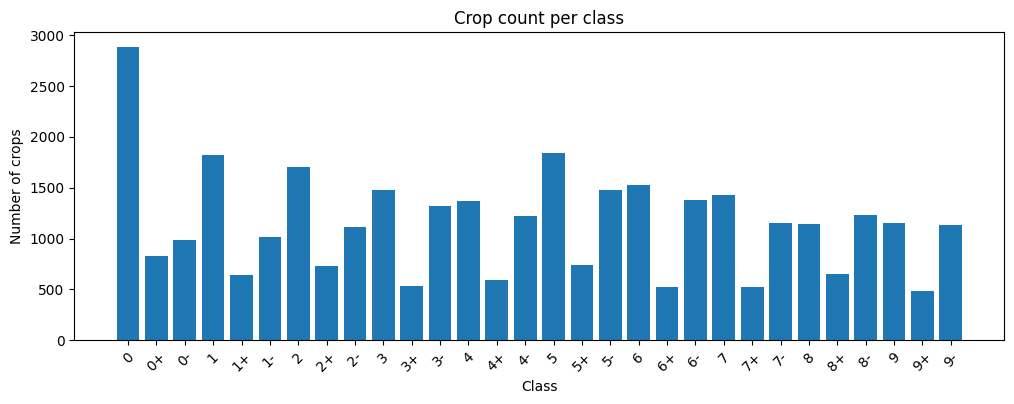

In [119]:
# Collect all saved crop image paths from each split folder
crop_files = []

for split_name in ["train", "val", "test"]:
    split_dir = os.path.join(pointers_out_dir, split_name)

    for filename in os.listdir(split_dir):
        if filename.endswith(".jpg"):
            crop_files.append(os.path.join(split_dir, filename))


# Count how many crops there are for each class label
class_counts = {}

for path in crop_files:
    filename = os.path.basename(path)
    name = os.path.splitext(filename)[0]

    # Pull the class label stored at end of filename
    label = name.rsplit("_", 1)[1]

    class_counts[label] = class_counts.get(label, 0) + 1


# Simple summary crops
print("Total crops:", len(crop_files))
print("Number of classes:", len(class_counts))
print()

for label in sorted(class_counts):
    print(label, ":", class_counts[label])


# Plot crop counts per class
labels = sorted(class_counts)
counts = [class_counts[label] for label in labels]

plt.figure(figsize=(12, 4))
plt.bar(labels, counts)
plt.xlabel("Class")
plt.ylabel("Number of crops")
plt.title("Crop count per class")
plt.xticks(rotation=45)
plt.show()

<a id="Visualise-cropping"></a>
<h4 style="color:#1fb4a7;">Check Cropped Images</h4>

Confirm that the crop, rotation, resize, and save steps worked correctly before continuing.

Total crops: 34627


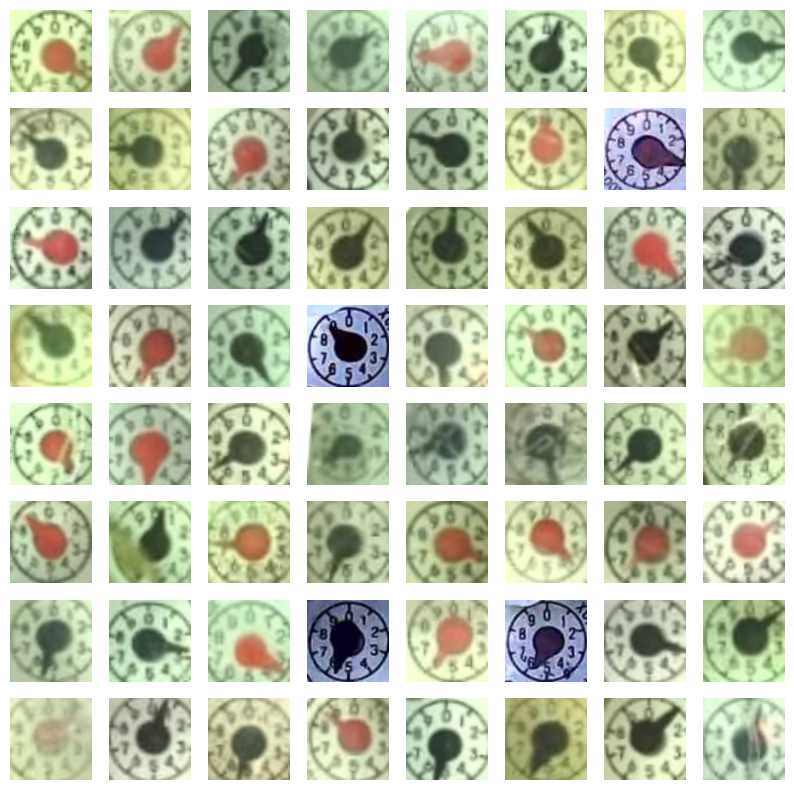

In [120]:
# Collect all saved crop image paths from each split folder
crop_files = []
for split_name in ["train", "val", "test"]:
    split_dir = os.path.join(pointers_out_dir, split_name)
    for file in os.listdir(split_dir):
        if file.endswith(".jpg"):
            crop_files.append(os.path.join(split_dir, file))

print("Total crops:", len(crop_files))

random.seed(42)
sample_crops = random.sample(crop_files, min(64, len(crop_files)))

plt.figure(figsize=(10, 10))

for i, path in enumerate(sample_crops):
    img = plt.imread(path)
    plt.subplot(8, 8, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.show()

<a id="Data-attrition"></a>
<h5 style="color:#4f7cff;">Data Attrition</h5>


Before crop: 35782
After crop: 34627
Crops dropped: 1155

Retained: 96.8%
Dropped: 3.2%

Drop reasons:
image not loaded: 0
pointer not parsed: 0
label not used: 1155
save failed: 0

image not loaded
Count: 0


<Figure size 1000x500 with 0 Axes>


pointer not parsed
Count: 0


<Figure size 1000x500 with 0 Axes>


label not used
Count: 1155


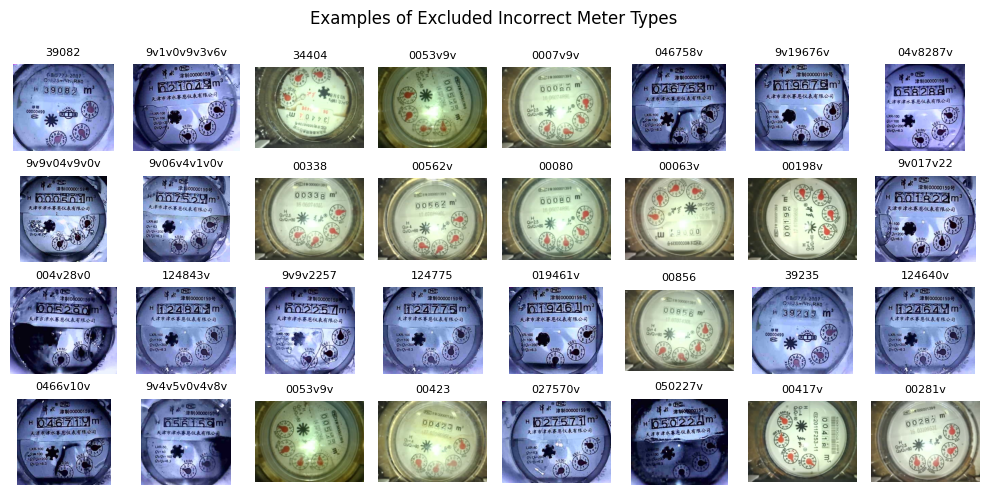


save failed
Count: 0


<Figure size 1000x500 with 0 Axes>

In [121]:
before = total_saved + total_skipped
after = total_saved
dropped = total_skipped

print()
print("Before crop:", before)
print("After crop:", after)
print("Crops dropped:", dropped)
print()
print(f"Retained: {100 * after / before:.1f}%")
print(f"Dropped: {100 * dropped / before:.1f}%")


# Count drops from stored examples
print()
print("Drop reasons:")

for reason, examples in drop_examples.items():
    print(f"{reason}: {len(examples)}")


# Show image examples from each dropped category
for reason, examples in drop_examples.items():
    print()
    print(reason)
    print("Count:", len(examples))

    shown = examples[:32]

    plt.figure(figsize=(10, 5))
    plt.suptitle("Examples of Excluded Incorrect Meter Types")

    for i, item in enumerate(shown):
        img = plt.imread(item["im_path"])

        plt.subplot(4, 8, i + 1)
        plt.imshow(img)
        plt.title(str(item["label"]), fontsize=8)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

<a id="Splitting"></a>
<h4 style="color:#1fb4a7;">Train / Validation / Test Split</h4>

This section prepares the cropped images for training.

Each text class label is changed into a number as PyTorch needs numeric labels.

Each record stores the image path and crop class number. Also used at the end for converting from prediction numeric back to label.

In [122]:
# Create the label mapping for later models


# Map class labels to numeric indexes. For input.
label_to_idx = {}

for i, label in enumerate(class_labels):
    label_to_idx[label] = i

# Map numeric indexes back to class labels. For output.
idx_to_label = {}

for label in label_to_idx:
    idx = label_to_idx[label]
    idx_to_label[idx] = label

num_classes = len(class_labels)

print("Number of classes:", num_classes)
print(label_to_idx)

Number of classes: 30
{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, '0-': 10, '1-': 11, '2-': 12, '3-': 13, '4-': 14, '5-': 15, '6-': 16, '7-': 17, '8-': 18, '9-': 19, '0+': 20, '1+': 21, '2+': 22, '3+': 23, '4+': 24, '5+': 25, '6+': 26, '7+': 27, '8+': 28, '9+': 29}


Build the records passed into the Dataset class.

Each record stores the crop image path and its numeric label, so the 
Dataset class can load the image and return the correct target during 
training.

Print sanity checks the final number of records in each split.

In [123]:
# Build path and label records for one split folder
def build_records(split_name):
    split_dir = os.path.join(pointers_out_dir, split_name)
    records = []

    for filename in sorted(os.listdir(split_dir)):

        # Get label from the end of the filename
        label = os.path.splitext(filename)[0].rsplit("_", 1)[1]

        # Store image path with its numeric class label
        path = os.path.join(split_dir, filename)
        records.append((path, label_to_idx[label]))

    return records


# Build records for each dataset split
train_records = build_records("train")
val_records = build_records("val")
test_records = build_records("test")


# Print final crop counts for each split
total = len(train_records) + len(val_records) + len(test_records)

print("Final split (per-crop counts):")
print(f"Train: {len(train_records)} ({100*len(train_records)/total:.1f}%)")
print(f"Val: {len(val_records)} ({100*len(val_records)/total:.1f}%)")
print(f"Test: {len(test_records)} ({100*len(test_records)/total:.1f}%)")

Final split (per-crop counts):
Train: 27672 (79.9%)
Val: 3458 (10.0%)
Test: 3497 (10.1%)


<a id="Transforms-Augmentation"></a>
<h5 style="color:#1fb4a7;">Transforms and Augmentation</h5>

The transform converts each image into tensor and normalises the 
RGB channels. This gives the model a consistent input format for CNN.

Augmentation is also appleid here. Training images use small random 
colour and rotation changes to reduce overfitting.

Augmentation is not done to validation and testing splits.

<a id="Normalise-crops"></a>
<h7 style="color:#4f7cff;">Normalise Cropped Images</h7>

This calculates the training sets own RGB averages and spread, so 
normalisation matches this dataset instead of using ImageNet based 
preset values. 

ImageNet values come from a broad general image dataset, 
while these dial crops are specific.

In [124]:
# Converts the image into numbers between 0 and 1
to_tensor = transforms.ToTensor()

# Init running totals for each RGB chan
channel_sum = torch.zeros(3)
channel_sq_sum = torch.zeros(3)
pixel_count = 0

# Read each training crop and add its RGB values to totals
for path, _ in tqdm(train_records):
    image = cv2.imread(path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    x = to_tensor(image)

    # Add pixel values for each RGB chan
    channel_sum += x.sum(dim=[1, 2])
    channel_sq_sum += (x ** 2).sum(dim=[1, 2])
    pixel_count += x.shape[1] * x.shape[2]

# Calc mean and std for each RGB chan
train_mean = channel_sum / pixel_count
train_std = (channel_sq_sum / pixel_count - train_mean ** 2).sqrt()

# Print values to use in the image normalisation transform
print("Train mean:", [round(v, 4) for v in train_mean.tolist()])
print("Train std: ", [round(v, 4) for v in train_std.tolist()])

100%|██████████| 27672/27672 [00:09<00:00, 2862.74it/s]

Train mean: [0.6187, 0.6531, 0.5496]
Train std:  [0.2019, 0.2177, 0.1931]


In [125]:

# Training transform includes augmentation and normalisation
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomRotation(degrees=10),
    transforms.Normalize(mean=train_mean.tolist(), std=train_std.tolist())
])

# These do not go through augmentation
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean.tolist(), std=train_std.tolist())
])

<a id="Check-Normalise-crops"></a>
<h7 style="color:#4f7cff;">Check Normalised Cropped Images</h7>

The displayed images are clamped between 0 and 1 so Matplotlib can 
show them purely for my own visual interest. 

During training, the model receives the unclamped normalised tensors, 
and the saved crop files are not changed.

Total crops: 34627


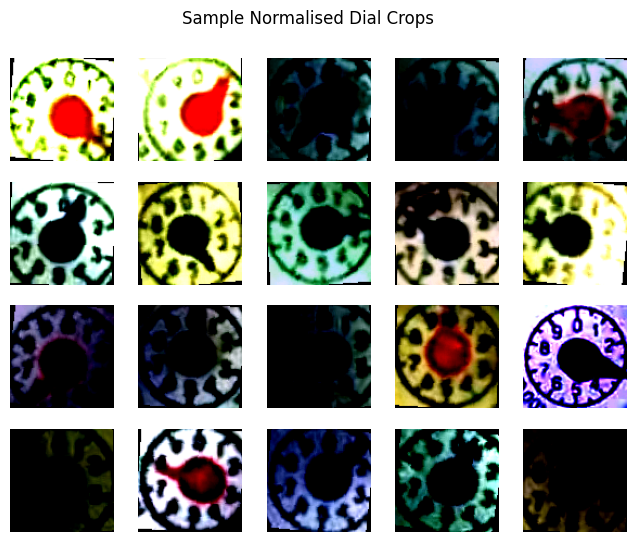

In [126]:
crop_files = []

for split_name in ["train", "val", "test"]:
    split_dir = os.path.join(pointers_out_dir, split_name)

    for file in os.listdir(split_dir):
        if file.endswith(".jpg"):
            crop_files.append(os.path.join(split_dir, file))

print("Total crops:", len(crop_files))

random.seed(42)
torch.manual_seed(42)

sample_crops = random.sample(crop_files, min(20, len(crop_files)))

plt.figure(figsize=(8, 6))
plt.suptitle("Sample Normalised Dial Crops")
plt.subplots_adjust(top=0.9)


for i, path in enumerate(sample_crops):
    img = Image.open(path).convert("RGB")

    # Apply full training transform including normalisation
    transformed_img = train_transform(img)

    # Convert from C x H x W to H x W x C for matplotlib
    display_img = transformed_img.permute(1, 2, 0)

    # Clip values only so matplotlib can display it
    # .clamp forces tensor values to stay between 0 and 1
    display_img = display_img.clamp(0, 1)

    plt.subplot(4, 5, i + 1)
    plt.imshow(display_img)
    plt.axis("off")

plt.show()

<a id="Dataset-class"></a>
<h5 style="color:#1fb4a7;">Dataset Class</h5>

Saved image paths are converted into PyTorch datasets and DataLoaders.

The custom <code>PointerCropDataset</code> class connects each saved 
crop path with its class label. 

DataLoader needs a Dataset class so it knows how to load one image and 
label at a time.

In [127]:
class PointerCropDataset(Dataset):
    """Load cropped pointer images. Each record is (path, label_idx)."""

    def __init__(self, records, transform=None):
        # Store image paths and labels
        self.records = records

        # Store image transforms
        self.transform = transform

    def __len__(self):
        # Return number of crop images
        return len(self.records)

    def __getitem__(self, index):
        # Get one image path and label
        path, label_idx = self.records[index]

        # Load image with OpenCV
        image = cv2.imread(path)

        # Convert OpenCV BGR image to RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Apply transforms if provided
        if self.transform is not None:
            image = self.transform(image)

        # Return image tensor and class label
        return image, label_idx

In [128]:
# Build PyTorch datasets
train_dataset = PointerCropDataset(train_records, transform=train_transform)
val_dataset = PointerCropDataset(val_records, transform=eval_transform)
test_dataset = PointerCropDataset(test_records, transform=eval_transform)

print("Dataset sizes:")
print("Train:", len(train_dataset))
print("Val: ", len(val_dataset))
print("Test: ", len(test_dataset))

Dataset sizes:
Train: 27672
Val:  3458
Test:  3497


<a id="Dataloaders"></a>
<h5 style="color:#1fb4a7;">Dataloaders</h5>

The DataLoaders then batch the data 
so it can be passed into the model during training and evaluation.

In [129]:
# DataLoader settings
batch_size = 64


train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    # Shuffle training data each epoch to reduce order bias
    shuffle=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
)

In [130]:
# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Example labels:", labels[:10])

Image batch shape: torch.Size([64, 3, 96, 96])
Label batch shape: torch.Size([64])
Example labels: tensor([ 3, 29,  5, 11,  1,  8, 28, 26, 25,  2])


<a id="Models"></a>
<h3 style="color:#1f77b4;">Model Architectures</h3>

Two architectures are compared in the same training
environment:

- **Benchmark - ResNet-18**
- **SOTA - EfficientNet-B0 + Coordinate Attention**

<a id="ResNet18"></a>
<h5 style="color:#1fb4a7;">ResNet-18</h5>

ResNet-18 is built from repeated BasicBlocks. Each BasicBlock uses two 
3x3 convolution layers, batch normalisation, and a skip connection that 
carries the input around the block.

The skip connection helps keep useful information from earlier layers. 
If the block changes the image size or number of channels, a 1x1 
convolution is used on the skip path so the shapes match before they are 
added together.

In [131]:
class BasicBlock(nn.Module):
    """ResNet-18 basic block: two 3x3 convs with a skip connection.

    If the input and output shapes already match, the skip path keeps the input
    unchanged. If the block changes size or channel count, a 1x1 convolution is
    used so the skip path matches the main path before they are added.
    """

    # BasicBlock keeps the final channel count the same.
    # Used by the ResNet builder so BasicBlock and bottleneck blocks 
    # can share code.
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        # Conv 1: changes channels and downsamples if needed
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)

        # Conv 2: keeps channels and spatial size
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Skip path: keep input if shapes match, otherwise resize with 1x1 conv
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = F.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        # Add the ORIGINAL input back before the final activation
        out = out + identity
        out = F.relu(out)

        return out

In [132]:
class ResNet18(nn.Module):
    """ResNet-18

    The model uses an initial layer, four groups of BasicBlocks, global average
    pooling, and a final fully connected classifier.

    Input shape : 3 x 96 x 96
    Output shape: num_classes logits
    """

    def __init__(self, num_classes=30):
        super().__init__()

        # Layer: 3 x 96 x 96 --> 64 x 24 x 24
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # Stage 1: 64 x 24 x 24 --> 64 x 24 x 24
        self.layer1 = self._make_stage(in_channels=64,  out_channels=64,  num_blocks=2, stride=1)

        # Stage 2: 64 x 24 x 24 --> 128 x 12 x 12
        self.layer2 = self._make_stage(in_channels=64,  out_channels=128, num_blocks=2, stride=2)

        # Stage 3: 128 x 12 x 12 --> 256 x 6 x 6
        self.layer3 = self._make_stage(in_channels=128, out_channels=256, num_blocks=2, stride=2)

        # Stage 4: 256 x 6 x 6 --> 512 x 3 x 3
        self.layer4 = self._make_stage(in_channels=256, out_channels=512, num_blocks=2, stride=2)

        # Head: 512 x 3 x 3 --> 512 --> num_classes
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    def _make_stage(self, in_channels, out_channels, num_blocks, stride):
        """Stack num_blocks BasicBlocks. Only the first block downsamples."""
        blocks = [BasicBlock(in_channels, out_channels, stride=stride)]
        for _ in range(num_blocks - 1):
            blocks.append(BasicBlock(out_channels, out_channels, stride=1))
        return nn.Sequential(*blocks)

    def forward(self, x):
        # Layer: 3 x 96 x 96 --> 64 x 24 x 24
        out = self.conv1(x)
        out = self.bn1(out)
        out = F.relu(out)
        out = self.maxpool(out)

        # Four residual stages
        # Each layer helps it learn progresively more details about the image
        # 64 x 24 x 24
        out = self.layer1(out)

        # 128 x 12 x 12
        out = self.layer2(out)

        # 256 x 6 x 6
        out = self.layer3(out)

        # 512 x 3 x 3
        out = self.layer4(out)

        # Classifier head
        # 512 x 1 x 1
        out = self.avgpool(out)

        # 512
        out = out.flatten(1)

        # num_classes
        out = self.fc(out)

        return out

<a id="EffNetB0"></a>
<h5 style="color:#1fb4a7;">EfficientNet-B0</h5>

EfficientNet-B0 is built from repeated MBConv blocks. Each block first expands the feature channels, applies convolution to learn spatial patterns, then uses Squeeze-and-Excitation (SE) to reweight the most useful channels.

The block then projects the channels back down and uses a residual connection when the input and output shapes match.

In [133]:
class SqueezeExcitation(nn.Module):
    """Reweight feature channels inside an MBConv block.

    The block summarises each channel, learns which channels are more useful,
    then scales the original feature map using those channel weights.
    """

    def __init__(self, in_channels, squeeze_channels):
        super().__init__()

        # Small bottleneck used to learn channel weights
        self.fc1 = nn.Conv2d(in_channels, squeeze_channels, kernel_size=1)
        self.act = nn.SiLU()
        self.fc2 = nn.Conv2d(squeeze_channels, in_channels, kernel_size=1)

    def forward(self, x):
        # Summarise each channel into one value
        scale = F.adaptive_avg_pool2d(x, 1)

        # Learn one weight per channel
        scale = self.fc1(scale)
        scale = self.act(scale)
        scale = self.fc2(scale)
        scale = torch.sigmoid(scale)

        # Apply the learned channel weights
        return x * scale

In [134]:
class MBConv(nn.Module):
    """Main EfficientNet block.

    The block expands the channels, applies a depthwise convolution, uses
    Squeeze-and-Excitation to reweight channels, then projects back to the
    output channel size. A residual connection is used when shapes match.
    """

    def __init__(self, in_channels, out_channels, kernel_size, stride, expand_ratio):
        super().__init__()

        # Use a residual connection only when the input and output shapes match
        self.use_residual = (stride == 1 and in_channels == out_channels)

        # Expanded channel size used inside the block
        hidden_dim = in_channels * expand_ratio
        layers = []

        # Expand channels with a 1x1 convolution when needed
        if expand_ratio != 1:
            layers += [
                nn.Conv2d(in_channels, hidden_dim, kernel_size=1, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.SiLU(),
            ]

        # Apply spatial filtering separately to each channel
        layers += [
            nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size,
                      stride=stride, padding=kernel_size // 2,
                      groups=hidden_dim, bias=False),
            nn.BatchNorm2d(hidden_dim),
            nn.SiLU(),
        ]

        # Reweight the most useful channels
        squeeze_channels = max(1, in_channels // 4)
        layers.append(SqueezeExcitation(hidden_dim, squeeze_channels))

        # Project back to the required output channels
        layers += [
            nn.Conv2d(hidden_dim, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
        ]

        self.block = nn.Sequential(*layers)

    def forward(self, x):
        # Run the main MBConv path
        out = self.block(x)

        # Add the skip connection when shapes match
        if self.use_residual:
            out = out + x

        return out

<a id="coord-att"></a>
<h5 style="color:#1fb4a7;">Coordinate Attention</h5>

A Coordinate Attention module is added near the end of the model helping it learn where features are located. This is useful for pointer classification because the pointer position matters.

In [135]:
class CoordAtt(nn.Module):
    """Coordinate Attention block.

    This block learns where important features are located along the height
    and width of the feature map. It is useful here because pointer position
    is important for classification.
    """

    def __init__(self, in_channels, out_channels, reduction=32):
        super().__init__()

        # Pool features separately along height and width
        self.pool_h = nn.AdaptiveAvgPool2d((None, 1))
        self.pool_w = nn.AdaptiveAvgPool2d((1, None))

        # Reduced channel size used inside the attention block
        mid = max(8, in_channels // reduction)

        # Shared transform for the height and width summaries
        self.conv1 = nn.Conv2d(in_channels, mid, kernel_size=1)
        self.bn1 = nn.BatchNorm2d(mid)
        self.act = nn.Hardswish()

        # Separate layers to create height and width attention maps
        self.conv_h = nn.Conv2d(mid, out_channels, kernel_size=1)
        self.conv_w = nn.Conv2d(mid, out_channels, kernel_size=1)

    def forward(self, x):
        identity = x
        _, _, h, w = x.size()

        # Create separate height and width summaries
        x_h = self.pool_h(x)
        x_w = self.pool_w(x).permute(0, 1, 3, 2)

        # Join the height and width summaries
        y = torch.cat([x_h, x_w], dim=2)

        # Learn a shared attention representation
        y = self.conv1(y)
        y = self.bn1(y)
        y = self.act(y)

        # Split back into height and width parts
        x_h, x_w = torch.split(y, [h, w], dim=2)
        x_w = x_w.permute(0, 1, 3, 2)

        # Create attention weights for height and width
        a_h = torch.sigmoid(self.conv_h(x_h))
        a_w = torch.sigmoid(self.conv_w(x_w))

        # Apply both attention maps to the original features
        return identity * a_h * a_w

<a id="effnet-coord-att"></a>
<h5 style="color:#1fb4a7;">EfficientNet-B0 + CoordAtt</h5>

In [136]:
class EfficientNetB0_CA(nn.Module):
    """EfficientNet-B0 model with Coordinate Attention.

    The model is built from MBConv blocks. Each MBConv block includes
    Squeeze-and-Excitation to reweight useful channels. Coordinate Attention
    is added near the end so the model can also focus on where important
    pointer features are located.

    Input shape : 3 x 96 x 96
    Output shape: num_classes logits
    """

    # EfficientNet-B0 stages: expand ratio, output channels, blocks, 
    # stride, kernel size
    config = [
        (1,  16, 1, 1, 3),
        (6,  24, 2, 2, 3),
        (6,  40, 2, 2, 5),
        (6,  80, 3, 2, 3),
        (6, 112, 3, 1, 5),
        (6, 192, 4, 2, 5),
        (6, 320, 1, 1, 3),
    ]

    def __init__(self, num_classes=30, dropout=0.2):
        super().__init__()

        # Initial feature extraction
        self.layer = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(),
        )

        # Build the MBConv stages
        stages = []
        in_channels = 32

        for expand_ratio, out_channels, num_blocks, stride, kernel_size in self.config:
            for i in range(num_blocks):

                # Only the first block in each stage may downsample
                block_stride = stride if i == 0 else 1

                stages.append(MBConv(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=kernel_size,
                    stride=block_stride,
                    expand_ratio=expand_ratio,
                ))

                in_channels = out_channels

        self.blocks = nn.Sequential(*stages)

        # Expand final feature channels before classification
        self.head_conv = nn.Sequential(
            nn.Conv2d(in_channels, 1280, kernel_size=1, bias=False),
            nn.BatchNorm2d(1280),
            nn.SiLU(),
        )

        # Add coordinate attention
        self.coord_att = CoordAtt(1280, 1280)

        # Final classifier
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(1280, num_classes),
        )

    def forward(self, x):
        # Extract low-level features
        out = self.layer(x)

        # Learn features through MBConv blocks
        out = self.blocks(out)

        # Expand final feature channels
        out = self.head_conv(out)

        # Reweight features using coordinate attention
        out = self.coord_att(out)

        # Pool and classify
        out = self.avgpool(out).flatten(1)
        out = self.classifier(out)

        return out

<a id="Check-models"></a>
<h5 style="color:#1fb4a7;">Check Models</h5>

Sanity checks of model architecture before training

In [137]:
# Build the models
resnet18 = ResNet18(num_classes=num_classes)
effnetb0 = EfficientNetB0_CA(num_classes=num_classes)

# --- TAKEN FROM COURSES UTILS.PY HELPER FILE ---
# Prints the total number of parameters in a neural network.
# Count the number of trainable parameters
def display_num_param(net):
    nb_param = 0

    for param in net.parameters():
        if param.requires_grad:
            nb_param += param.numel()

    print("There are {} ({:.2f} million) trainable parameters in this neural network".format(
        nb_param, nb_param / 1e6
    ))

    return nb_param


# Display models param numbers
print("ResNet-18 benchmark model:")
display_num_param(resnet18)

print("\nEfficientNet-B0 + Coordinate Attention model:")
display_num_param(effnetb0)


# Send the models to the same device used for training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("\nDevice:", device)

resnet18 = resnet18.to(device)
effnetb0 = effnetb0.to(device)


# Check one batch flows through both models correctly
images, labels = next(iter(train_loader))
images = images.to(device)

resnet18.eval()
effnetb0.eval()

with torch.no_grad():
    out_resnet = resnet18(images)
    out_effnet = effnetb0(images)

print("\nBatch image shape:", images.shape)
print("ResNet-18 output shape:", out_resnet.shape)
print("EfficientNet-B0 + CA output shape:", out_effnet.shape)

ResNet-18 benchmark model:
There are 11191902 (11.19 million) trainable parameters in this neural network

EfficientNet-B0 + Coordinate Attention model:
There are 4202258 (4.20 million) trainable parameters in this neural network

Device: cuda

Batch image shape: torch.Size([64, 3, 96, 96])
ResNet-18 output shape: torch.Size([64, 30])
EfficientNet-B0 + CA output shape: torch.Size([64, 30])


<a id="Training"></a>
<h3 style="color:#1f77b4;">Training</h3>



<a id="Train-help"></a>
<h5 style="color:#1fb4a7;">Training Helpers</h5>

The same training pipeline is reused for the three runs: ResNet-18 (benchmark), 
EfficientNet-B0 + CA (chosen method), and EfficientNet-B0 without CA (comparison).

<ul>
    <li><code>get_error()</code> returns the fraction of incorrect predictions in a batch (taken from the course utils.py helper).</li>
    <li><code>eval_on_set()</code> runs forward propagation, returns average loss and error.</li>
    <li><code>train_model()</code> trains a network, records per-epoch training and validation loss and error, and saves the checkpoint with lowest validation error.</li>
</ul>

In [138]:
# Loss criterion shared across all training runs
criterion = nn.CrossEntropyLoss()


# --- TAKEN FROM COURSES UTILS.PY HELPER FILE ---
# Calculates the error rate as the fraction of incorrect predictions.
def get_error(scores, labels):

    bs = scores.size(0)
    predicted_labels = scores.argmax(dim=1)
    indicator = (predicted_labels == labels)
    num_matches = indicator.sum()

    return 1 - num_matches.float() / bs

# --- REUSED FROM MY ASSESS1.2 ---
def eval_on_set(net, loader):
    """
    REUSED FROM MY ASSESS1.2: Added return total_loss aswell as error.

    Evaluate a NN on a dataset. Computes both loss and error.

    Sets the network to evaluation mode, runs forward propagation,
    calculates loss and prediction error for each minibatch, returns
    average loss and error.

    Parameters:
        net:
            Neural network for testing.
        loader:
            DataLoader to evaluate on.

    Returns:
        tuple:
            Average loss and average error across all minibatches.
    """

    # Set network in evaluation mode
    net.eval()

    running_loss = 0
    running_error = 0
    num_batches = 0

    with torch.no_grad():
        for minibatch_data, minibatch_label in loader:

            # send them to the gpu
            minibatch_data = minibatch_data.to(device)
            minibatch_label = minibatch_label.to(device)

            # Forward propagation
            scores = net(minibatch_data)

            # Compute loss on this batch
            loss = criterion(scores, minibatch_label)
            running_loss += loss.item()

            # Compute error on this batch
            error = get_error(scores, minibatch_label)
            running_error += error.item()

            num_batches += 1

    total_loss = running_loss / num_batches
    total_error = running_error / num_batches

    return total_loss, total_error


# --- ADAPTED FROM MY ASSESS1.2 ---
def train_model(net, optimizer, scheduler, num_epochs, run_name):
    """
    ADAPTED FROM MY ASSESS1.2: Added best checkpoint saving, CSV history,
    validation loss tracking and set epoch.

    Train NN for a chosen number of epochs. Computes training loss and error,
    evaluates on the validation set after each epoch, and saves the best model
    based on validation error.

    Per-epoch training and validation loss and error are recorded so training
    curves can be plotted later.

    Parameters:
        net:
            NN model to train.
        optimizer:
            Update model parameters.
        scheduler:
            Learning rate scheduler used to decay learning rate.
        num_epochs:
            Number of training epochs.
        run_name:
            Name used when saving checkpoint and CSV history files.

    Returns:
        dict:
            Training history containing training and validation loss/error,
            best checkpoint details, and total training time.
    """

    # For storing training and validation history
    history = {
        'train_loss': [],
        'train_error': [],
        'val_loss': [],
        'val_error': [],
    }

    # Track best validation error
    best_val_error = float('inf')
    best_epoch = 0
    checkpoint_path = f'{run_name}_best.pth'

    # Tracking total time
    start = time.time()

    # Train for selected number of epochs
    for epoch in range(1, num_epochs + 1):

        # Track time for this epoch
        epoch_start = time.time()

        # Set training mode
        net.train()

        running_loss  = 0
        running_error = 0
        num_batches   = 0

        # Training loop for each minibatch
        # Tqdm is used to monitor the progress of the training process
        for minibatch_data, minibatch_label in tqdm(train_loader, desc=f'{run_name} epoch {epoch}/{num_epochs}'):

            # Send data and labels to the gpu
            minibatch_data = minibatch_data.to(device)
            minibatch_label = minibatch_label.to(device)

            # Set the gradients to zeros
            optimizer.zero_grad()

            # Forward prop
            scores = net(minibatch_data)

            # Compute the average loss for this minibatch
            loss = criterion(scores, minibatch_label)

            # Backward pass
            loss.backward()

            # Do one step of stochastic gradient descent
            optimizer.step()

            # Track loss of each batch
            running_loss += loss.detach().item()

            # Compute the error made on this batch and add it to the running error
            error = get_error(scores.detach(), minibatch_label)
            running_error += error.item()

            num_batches += 1

        # Compute stats for full training set
        train_loss = running_loss / num_batches
        train_error = running_error / num_batches

        # Evaluate on the validation set
        val_loss, val_error = eval_on_set(net, val_loader)

        # Store epoch results for plotting later
        history['train_loss'].append(train_loss)
        history['train_error'].append(train_error)
        history['val_loss'].append(val_loss)
        history['val_error'].append(val_error)

        # Time for this epoch
        epoch_time = time.time() - epoch_start

        # Total time so far
        elapsed = time.time() - start

        print('epoch=', epoch,
              '\t epoch_time=', round(epoch_time, 2), 'seconds',
              '\t total_time=', round(elapsed / 60, 2), 'minutes',
              '\t train_loss=', round(train_loss, 4),
              '\t train_error=', round(train_error * 100, 2), 'percent',
              '\t val_loss=', round(val_loss, 4),
              '\t val_error=', round(val_error * 100, 2), 'percent',
              '\t lr=', optimizer.param_groups[0]['lr'])

        # Decay the learning rate according to the scheduler
        scheduler.step()

        # Save the model whenever validation error improves
        if val_error < best_val_error:
            best_val_error = val_error
            best_epoch = epoch

            torch.save(net.state_dict(), checkpoint_path)
            print(' - new best, saved', checkpoint_path)

    # Final total time after all epochs
    total_training_time = time.time() - start

    print('Total training time:', round(total_training_time / 60, 2), 'minutes')
    print('Best val_error:', round(best_val_error * 100, 2), 'percent at epoch', best_epoch)

    # Save the training history to a CSV file for report/visualisations
    csv_path = f'{run_name}_history.csv'

    with open(csv_path, 'w', newline='') as f:

        # Create CSV writer
        writer = csv.writer(f)

        # Write the column names
        header = ['epoch', 'train_loss', 'train_error', 'val_loss', 'val_error']
        writer.writerow(header)

        # Write one row for each epoch
        for i in range(num_epochs):

            epoch_number = i + 1
            train_loss = history['train_loss'][i]
            train_error = history['train_error'][i]
            val_loss = history['val_loss'][i]
            val_error = history['val_error'][i]

            row = [epoch_number, train_loss, train_error, val_loss, val_error]

            writer.writerow(row)

    # Store best checkpoint information
    history['best_epoch'] = best_epoch
    history['best_val_error'] = best_val_error
    history['checkpoint_path'] = checkpoint_path
    history['total_training_time'] = total_training_time

    return history

<a id="hyper-params"></a>
<h5 style="color:#1fb4a7;">Hyperparameters</h5>

In [ ]:
# Fix the seed so each training run starts from the same weight init
torch.manual_seed(42)

# --- Hyperparameters shared across all training runs ---
num_epochs = 50
my_lr = 0.01
weight_decay = 5e-4
gamma = 0.1

# Reduce learning rate at epochs 25 and 40 to help the model settle
milestones = [25, 40]


<a id="Train-resnet18"></a>
<h5 style="color:#1fb4a7;">Train ResNet-18 (Benchmark)</h5>

In [140]:
# Rebuild the benchmark model so training starts from fresh weights
resnet18 = ResNet18(num_classes=num_classes).to(device)
display_num_param(resnet18)

# Set optimiser and scheduler for ResNet-18
resnet_optimizer = torch.optim.SGD(
    resnet18.parameters(),
    lr=my_lr,
    momentum=0.9,
    weight_decay=weight_decay,
)
resnet_scheduler = optim.lr_scheduler.MultiStepLR(
    resnet_optimizer,
    milestones=milestones,
    gamma=gamma,
)


# Train the ResNet-18 benchmark
resnet18_history = train_model(
    resnet18,
    resnet_optimizer,
    resnet_scheduler,
    num_epochs=num_epochs,
    run_name='resnet18',
)

There are 11191902 (11.19 million) trainable parameters in this neural network


resnet18 epoch 1/50: 100%|██████████| 433/433 [01:03<00:00,  6.86it/s]


epoch= 1 	 epoch_time= 65.11 seconds 	 total_time= 1.09 minutes 	 train_loss= 1.0803 	 train_error= 37.63 percent 	 val_loss= 0.6833 	 val_error= 26.36 percent 	 lr= 0.01
 - new best, saved resnet18_best.pth


resnet18 epoch 2/50: 100%|██████████| 433/433 [01:01<00:00,  7.10it/s]


epoch= 2 	 epoch_time= 62.99 seconds 	 total_time= 2.14 minutes 	 train_loss= 0.5672 	 train_error= 22.34 percent 	 val_loss= 0.4567 	 val_error= 17.93 percent 	 lr= 0.01
 - new best, saved resnet18_best.pth


...

epoch= 48 	 epoch_time= 61.96 seconds 	 total_time= 49.82 minutes 	 train_loss= 0.042 	 train_error= 1.25 percent 	 val_loss= 0.3015 	 val_error= 9.29 percent 	 lr= 0.0001


resnet18 epoch 49/50: 100%|██████████| 433/433 [00:59<00:00,  7.23it/s]


epoch= 49 	 epoch_time= 61.89 seconds 	 total_time= 50.85 minutes 	 train_loss= 0.0421 	 train_error= 1.29 percent 	 val_loss= 0.2991 	 val_error= 9.32 percent 	 lr= 0.0001


resnet18 epoch 50/50: 100%|██████████| 433/433 [00:59<00:00,  7.22it/s]


epoch= 50 	 epoch_time= 62.06 seconds 	 total_time= 51.88 minutes 	 train_loss= 0.0416 	 train_error= 1.26 percent 	 val_loss= 0.2996 	 val_error= 9.18 percent 	 lr= 0.0001
Total training time: 51.88 minutes
Best val_error: 8.98 percent at epoch 43


<a id="Train-effnet-ca"></a>
<h5 style="color:#1fb4a7;">Train EfficientNet-B0 + CA (Chosen Method)</h5>

In [141]:
# Fix the seed so each training run starts from the same weight init
torch.manual_seed(42)

# Rebuild the EfficientNet-B0 + CA model
effnet_ca = EfficientNetB0_CA(num_classes=num_classes).to(device)
display_num_param(effnet_ca)

# Set optimiser and scheduler. Same hyperparameters as ResNet-18 for fair comparison.
effnet_ca_optimizer = torch.optim.SGD(
    effnet_ca.parameters(),
    lr=my_lr,
    momentum=0.9,
    weight_decay=weight_decay,
)
effnet_ca_scheduler = optim.lr_scheduler.MultiStepLR(
    effnet_ca_optimizer,
    milestones=milestones,
    gamma=gamma,
)


# Train EfficientNet-B0 + CA
effnet_ca_history = train_model(
    effnet_ca,
    effnet_ca_optimizer,
    effnet_ca_scheduler,
    num_epochs=num_epochs,
    run_name='effnetb0_ca',
)

There are 4202258 (4.20 million) trainable parameters in this neural network


effnetb0_ca epoch 1/50: 100%|██████████| 433/433 [01:03<00:00,  6.78it/s]


epoch= 1 	 epoch_time= 66.09 seconds 	 total_time= 1.1 minutes 	 train_loss= 2.6465 	 train_error= 74.87 percent 	 val_loss= 1.0241 	 val_error= 34.12 percent 	 lr= 0.01
 - new best, saved effnetb0_ca_best.pth


effnetb0_ca epoch 2/50: 100%|██████████| 433/433 [01:03<00:00,  6.81it/s]


epoch= 2 	 epoch_time= 65.71 seconds 	 total_time= 2.2 minutes 	 train_loss= 0.7869 	 train_error= 29.35 percent 	 val_loss= 0.553 	 val_error= 21.56 percent 	 lr= 0.01
 - new best, saved effnetb0_ca_best.pth


...

epoch= 48 	 epoch_time= 70.47 seconds 	 total_time= 56.09 minutes 	 train_loss= 0.0671 	 train_error= 2.01 percent 	 val_loss= 0.2999 	 val_error= 10.4 percent 	 lr= 0.0001


effnetb0_ca epoch 49/50: 100%|██████████| 433/433 [01:07<00:00,  6.38it/s]


epoch= 49 	 epoch_time= 70.08 seconds 	 total_time= 57.25 minutes 	 train_loss= 0.0688 	 train_error= 2.1 percent 	 val_loss= 0.2996 	 val_error= 10.0 percent 	 lr= 0.0001


effnetb0_ca epoch 50/50: 100%|██████████| 433/433 [01:07<00:00,  6.41it/s]


epoch= 50 	 epoch_time= 69.71 seconds 	 total_time= 58.42 minutes 	 train_loss= 0.0678 	 train_error= 1.93 percent 	 val_loss= 0.3022 	 val_error= 10.23 percent 	 lr= 0.0001
Total training time: 58.42 minutes
Best val_error: 9.55 percent at epoch 37


<a id="Train-effnet-noca"></a>
<h5 style="color:#1fb4a7;">Train EfficientNet-B0 without CA (Comparison)</h5>

In [142]:
# Fix the seed so each training run starts from the same weight init
torch.manual_seed(42)

# Rebuild the EfficientNet-B0 model and remove the CoordAtt block.
# Replacing it with nn.Identity() keeps the forward pass intact without
# requiring a separate class definition.
effnet_no_ca = EfficientNetB0_CA(num_classes=num_classes).to(device)

# I know better OOP is to use a cosntructor flag ie, "use_ca=True", but
# I figure this is just a simple comparison so its fine.
effnet_no_ca.coord_att = nn.Identity()
display_num_param(effnet_no_ca)

# Set optimiser and scheduler. Same hyperparameters as the other two runs.
effnet_no_ca_optimizer = torch.optim.SGD(
    effnet_no_ca.parameters(),
    lr=my_lr,
    momentum=0.9,
    weight_decay=weight_decay,
)
effnet_no_ca_scheduler = optim.lr_scheduler.MultiStepLR(
    effnet_no_ca_optimizer,
    milestones=milestones,
    gamma=gamma,
)


# Train EfficientNet-B0 without CA
effnet_no_ca_history = train_model(
    effnet_no_ca,
    effnet_no_ca_optimizer,
    effnet_no_ca_scheduler,
    num_epochs=num_epochs,
    run_name='effnetb0_no_ca',
)

There are 4045978 (4.05 million) trainable parameters in this neural network


effnetb0_no_ca epoch 1/50: 100%|██████████| 433/433 [01:06<00:00,  6.52it/s]


epoch= 1 	 epoch_time= 68.57 seconds 	 total_time= 1.14 minutes 	 train_loss= 1.5849 	 train_error= 50.77 percent 	 val_loss= 0.6626 	 val_error= 26.85 percent 	 lr= 0.01
 - new best, saved effnetb0_no_ca_best.pth


effnetb0_no_ca epoch 2/50: 100%|██████████| 433/433 [01:06<00:00,  6.50it/s]


epoch= 2 	 epoch_time= 68.71 seconds 	 total_time= 2.29 minutes 	 train_loss= 0.6286 	 train_error= 24.49 percent 	 val_loss= 0.5169 	 val_error= 19.72 percent 	 lr= 0.01
 - new best, saved effnetb0_no_ca_best.pth


...

epoch= 48 	 epoch_time= 68.63 seconds 	 total_time= 54.99 minutes 	 train_loss= 0.0528 	 train_error= 1.77 percent 	 val_loss= 0.3104 	 val_error= 9.74 percent 	 lr= 0.0001


effnetb0_no_ca epoch 49/50: 100%|██████████| 433/433 [01:06<00:00,  6.47it/s]


epoch= 49 	 epoch_time= 69.05 seconds 	 total_time= 56.14 minutes 	 train_loss= 0.055 	 train_error= 1.86 percent 	 val_loss= 0.3101 	 val_error= 9.91 percent 	 lr= 0.0001


effnetb0_no_ca epoch 50/50: 100%|██████████| 433/433 [01:06<00:00,  6.54it/s]


epoch= 50 	 epoch_time= 68.33 seconds 	 total_time= 57.28 minutes 	 train_loss= 0.0524 	 train_error= 1.66 percent 	 val_loss= 0.3115 	 val_error= 9.86 percent 	 lr= 0.0001
Total training time: 57.28 minutes
Best val_error: 9.57 percent at epoch 26


<a id="Train-curves"></a>
<h5 style="color:#1fb4a7;">Training Curves</h5>

Per-epoch training and validation loss and error are plotted for the three 
runs. The training curves are used to check whether each model converged, 
to compare convergence speed, and look for overfitting (validation error stops 
tracking training error.)

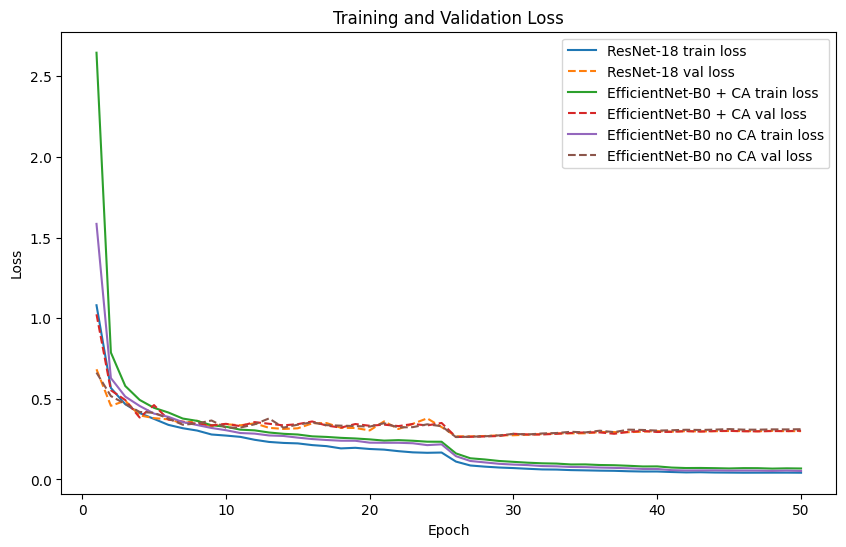

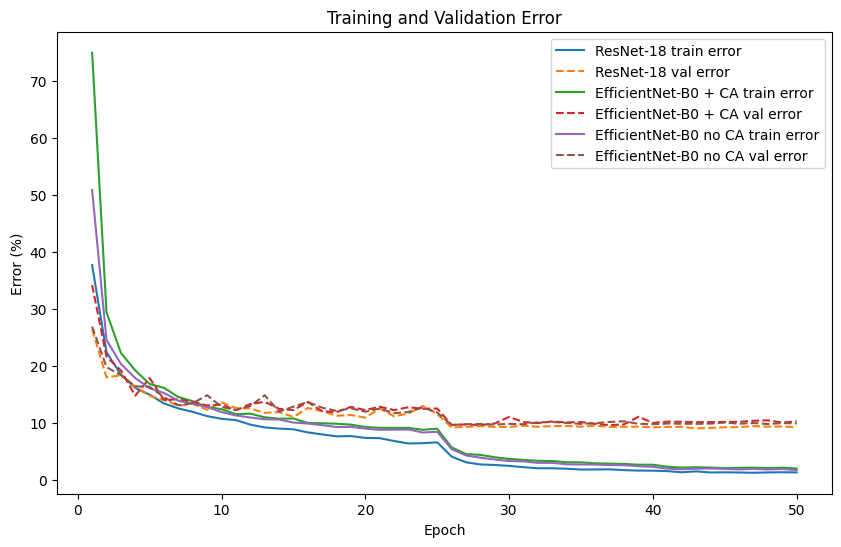

Best validation error per run:
ResNet-18 	 val_error = 8.977272727272727 percent 	 epoch = 43 	 total time = 51.88377470970154 min
EfficientNet-B0 + CA 	 val_error = 9.545454545454547 percent 	 epoch = 37 	 total time = 58.4160829226176 min
EfficientNet-B0 no CA 	 val_error = 9.573863636363637 percent 	 epoch = 26 	 total time = 57.27589060465495 min


In [143]:
# Collect training histories
runs = [
    ('ResNet-18', resnet18_history),
    ('EfficientNet-B0 + CA', effnet_ca_history),
    ('EfficientNet-B0 no CA', effnet_no_ca_history),
]


# Plot training and validation loss
plt.figure(figsize=(10, 6))

for name, hist in runs:
    epochs = range(1, len(hist['train_loss']) + 1)

    plt.plot(epochs, hist['train_loss'], label=name + ' train loss')
    plt.plot(epochs, hist['val_loss'], linestyle='--', label=name + ' val loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()


# Plot training and validation error
plt.figure(figsize=(10, 6))

for name, hist in runs:
    epochs = range(1, len(hist['train_error']) + 1)

    train_error = [error * 100 for error in hist['train_error']]
    val_error = [error * 100 for error in hist['val_error']]

    plt.plot(epochs, train_error, label=name + ' train error')
    plt.plot(epochs, val_error, linestyle='--', label=name + ' val error')

plt.xlabel('Epoch')
plt.ylabel('Error (%)')
plt.title('Training and Validation Error')
plt.legend()
plt.show()


# Print best validation error for each model
print('Best validation error per run:')

for name, hist in runs:
    print(name,
          '\t val_error =', hist['best_val_error'] * 100, 'percent',
          '\t epoch =', hist['best_epoch'],
          '\t total time =', hist['total_training_time'] / 60, 'min')

<a id="Evaluation"></a>
<h3 style="color:#1f77b4;">Evaluation</h3>

Evaluate the 3 models on the test set using
the best validation-error checkpoint saved during training.

The same test set, batch size, and device are used.

<a id="Load-best"></a>
<h5 style="color:#1fb4a7;">Load Best Checkpoints</h5>

EfficientNet without CA checkpoint doesnt have <code>coord_att</code>
weights, <code>nn.Identity()</code> during training is
applied before loading.

In [144]:
def load_best(net, checkpoint_path):
    """Load saved best weights into a network and set evaluation mode."""
    net.load_state_dict(torch.load(checkpoint_path, map_location=device))
    net.eval()
    return net


# Rebuild each architecture and load its best checkpoint
# --- ResNet-18 benchmark ---
resnet18_best = ResNet18(num_classes=num_classes).to(device)
resnet18_best = load_best(resnet18_best, resnet18_history['checkpoint_path'])

# --- EfficientNet-B0 + CA chosen method ---
effnet_ca_best = EfficientNetB0_CA(num_classes=num_classes).to(device)
effnet_ca_best = load_best(effnet_ca_best, effnet_ca_history['checkpoint_path'])

# --- EfficientNet-B0 without CA comparison ---
# Match the training architecture by replacing CoordAtt with Identity
# before loading so state_dict keys line up.
effnet_no_ca_best = EfficientNetB0_CA(num_classes=num_classes).to(device)
effnet_no_ca_best.coord_att = nn.Identity().to(device)
effnet_no_ca_best = load_best(effnet_no_ca_best, effnet_no_ca_history['checkpoint_path'])


# Group the loaded models for reuse in the evaluation cells below
loaded_models = [
    ('ResNet-18', resnet18_best, resnet18_history),
    ('EfficientNet-B0 + CA', effnet_ca_best, effnet_ca_history),
    ('EfficientNet-B0 no CA', effnet_no_ca_best, effnet_no_ca_history),
]

print('Loaded checkpoints:')
for name, _, hist in loaded_models:
    print(name,
          '\t best_epoch =', hist['best_epoch'],
          '\t best_val_error =', round(hist['best_val_error'] * 100, 2), 'percent')

Loaded checkpoints:
ResNet-18 	 best_epoch = 43 	 best_val_error = 8.98 percent
EfficientNet-B0 + CA 	 best_epoch = 37 	 best_val_error = 9.55 percent
EfficientNet-B0 no CA 	 best_epoch = 26 	 best_val_error = 9.57 percent


<a id="Test-metrics"></a>
<h5 style="color:#1fb4a7;">Test-set Metrics</h5>

Used following metrics:

<ul>
    <li><strong>Accuracy</strong> - correct test predictions.</li>
    <li><strong>Mean class F1</strong> - F1 averaged equally across the 30 classes.
        Useful because per-class counts vary in this dataset.</li>
    <li><strong>Per-class precision and recall</strong> - shows whether
        any single dial class is much harder than the others.</li>
</ul>

<code>collect_predictions()</code> runs forward propagation over the test
loader once and stores the predicted and true labels for later evaluation.

In [145]:

def collect_predictions(net, loader):
    """
    ADAPTED FROM MY ASSESS1.2: Added prediction collection for later metrics and error analysis.

    Run a trained NN on a dataset and collect predicted and true class labels.

    Sets the network to evaluation mode, runs forward propagation,
    takes the predicted class for each minibatch, and returns all predictions
    and labels as numpy arrays.

    Parameters:
        net:
            Neural network for prediction.
        loader:
            DataLoader to evaluate on.

    Returns:
        tuple:
            Predicted labels and true labels as 1D numpy arrays.
    """

    # Set network in evaluation mode
    net.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for minibatch_data, minibatch_label in loader:

            # send them to the gpu
            minibatch_data = minibatch_data.to(device)
            minibatch_label = minibatch_label.to(device)

            # Forward propagation
            scores = net(minibatch_data)

            # Take the predicted class with the highest score
            preds = scores.argmax(dim=1)

            all_preds.append(preds.cpu())
            all_labels.append(minibatch_label.cpu())

    # Concatenate batches into single arrays
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    return all_preds, all_labels


def per_class_metrics(preds, labels, num_classes):
    """Compute per-class precision, recall, F1 and support.

    Support is how many true examples there are for each class

    Parameters:
        preds:
            Predicted class indices (1D numpy array).
        labels:
            True class indices (1D numpy array).
        num_classes:
            Number of dial classes.

    Returns:
        tuple:
            (precision, recall, f1, support)
    """

    precision = np.zeros(num_classes)
    recall = np.zeros(num_classes)
    f1 = np.zeros(num_classes)
    support = np.zeros(num_classes, dtype=int)

    for c in range(num_classes):

        # Count true positives, false positives, false negatives for class c
        tp = int(((preds == c) & (labels == c)).sum())
        fp = int(((preds == c) & (labels != c)).sum())
        fn = int(((preds != c) & (labels == c)).sum())

        support[c] = int((labels == c).sum())

        # Avoid division by zero if a class has no examples
        precision[c] = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall[c] = tp / (tp + fn) if (tp + fn) > 0 else 0.0

        if precision[c] + recall[c] > 0:
            f1[c] = 2 * precision[c] * recall[c] / (precision[c] + recall[c])
        else:
            f1[c] = 0.0

    return precision, recall, f1, support


# Run predictions once per model and store with the existing loaded_models tuples
results = {}

for name, net, _ in loaded_models:

    preds, labels = collect_predictions(net, test_loader)
    accuracy = (preds == labels).mean()

    precision, recall, f1, support = per_class_metrics(preds, labels, num_classes)

    mean_class_precision = precision.mean()
    mean_class_recall = recall.mean()
    mean_class_f1 = f1.mean()

    results[name] = {
        'preds': preds,
        'labels': labels,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'support': support,
        'mean_class_precision': mean_class_precision,
        'mean_class_recall': mean_class_recall,
        'mean_class_f1': mean_class_f1,
    }

    print(name,
          '\t accuracy =', round(accuracy * 100, 2), 'percent',
          '\t mean_class_precision =', round(mean_class_precision, 4),
          '\t mean_class_recall =', round(mean_class_recall, 4),
          '\t mean_class_f1 =', round(mean_class_f1, 4))

ResNet-18 	 accuracy = 88.82 percent 	 mean_class_precision = 0.8674 	 mean_class_recall = 0.8568 	 mean_class_f1 = 0.8605
EfficientNet-B0 + CA 	 accuracy = 88.56 percent 	 mean_class_precision = 0.8659 	 mean_class_recall = 0.8552 	 mean_class_f1 = 0.8587
EfficientNet-B0 no CA 	 accuracy = 88.25 percent 	 mean_class_precision = 0.8601 	 mean_class_recall = 0.8529 	 mean_class_f1 = 0.8557


<a id="McNemar"></a>
<h5 style="color:#1fb4a7;">McNemar</h5>

In [146]:
def run_mcnemar(results, name_a, name_b):
    """Run McNemars test to compare two models on the same test set."""
    
    # Get the true labels and predictions for both models
    y_true = results[name_a]["labels"]
    pred_a = results[name_a]["preds"]
    pred_b = results[name_b]["preds"]

    # Paired correct/incorrect comparison table
    table = mcnemar_table(
        y_target=y_true,
        y_model1=pred_a,
        y_model2=pred_b
    )

    # Run test with continuity correction. This is a more conservative
    # formula recommended for when evidence is borderline.
    chi2, p_value = mcnemar(
        ary=table,
        exact=False,
        corrected=True
    )

    print(name_a, "vs", name_b)
    print("table =", table)
    print("chi2 =", round(chi2, 4))
    print("p-value =", round(p_value, 4))

run_mcnemar(results, "EfficientNet-B0 + CA", "EfficientNet-B0 no CA")
print()
run_mcnemar(results, "EfficientNet-B0 + CA", "ResNet-18")

EfficientNet-B0 + CA vs EfficientNet-B0 no CA
table = [[2982  115]
 [ 104  296]]
chi2 = 0.4566
p-value = 0.4992

EfficientNet-B0 + CA vs ResNet-18
table = [[3007   90]
 [  99  301]]
chi2 = 0.3386
p-value = 0.5606


<a id="Confusion-matrices"></a>
<h5 style="color:#1fb4a7;">Confusion Matrices</h5>

Show how predictions are spread across classes. 
Strong diagonal = mostly correct. Off-diagonal hotspots show which
dial classes get confused with which.

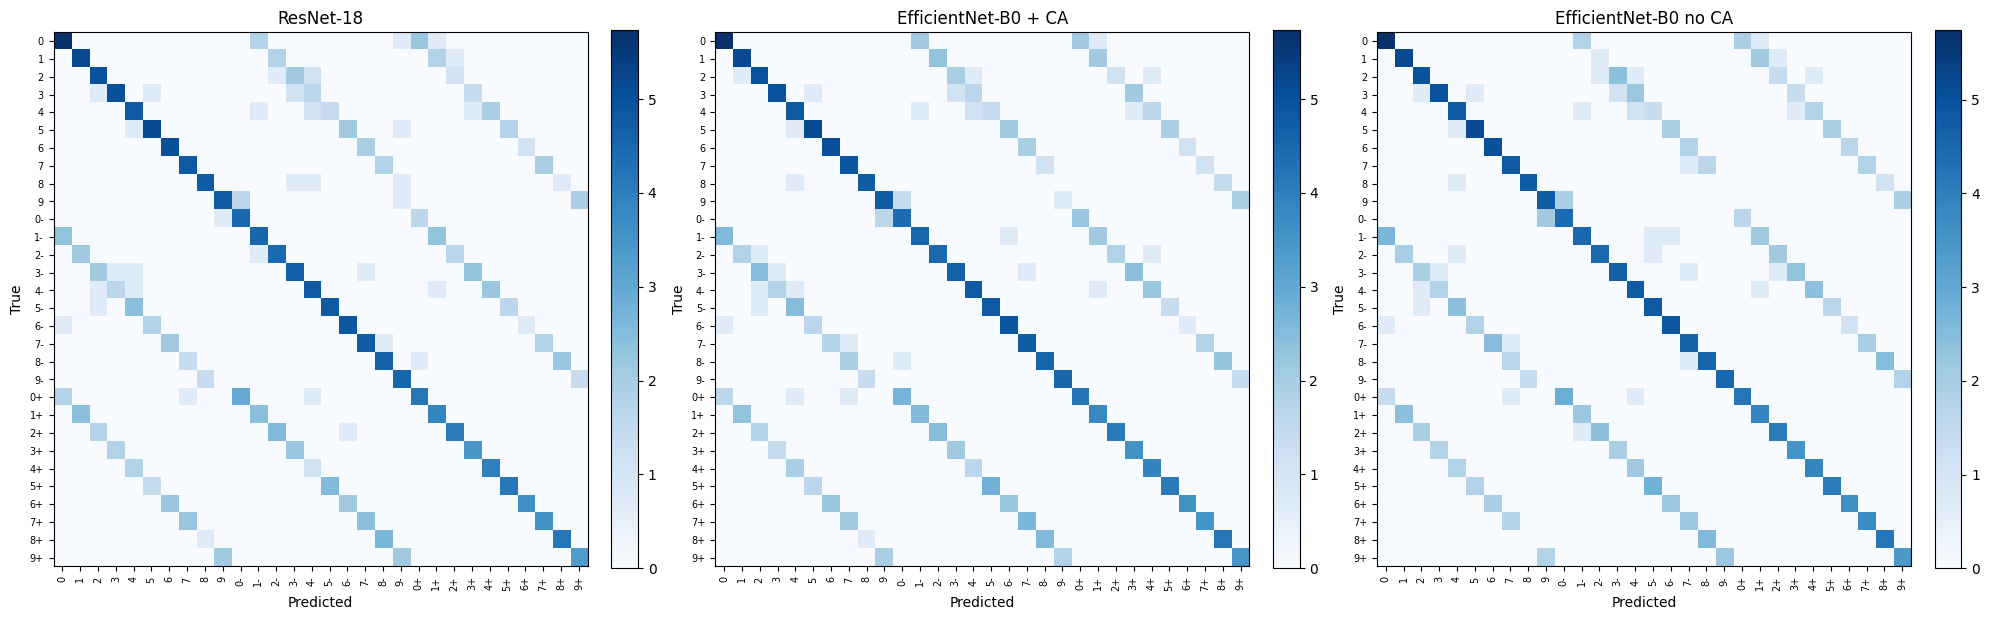


Top five off-diagonal errors (EfficientNet-B0 + CA):
true = 5+ 	 predicted = 5- 	 count = 15
true = 0+ 	 predicted = 0- 	 count = 14
true = 7+ 	 predicted = 7- 	 count = 13
true = 8+ 	 predicted = 8- 	 count = 12
true = 1- 	 predicted = 0 	 count = 12


In [147]:
def confusion_matrix(preds, labels, num_classes):
    """Build a num_classes x num_classes confusion matrix.
        Rows = true class
        columns = predicted class.
    """

    cm = np.zeros((num_classes, num_classes), dtype=int)

    for i in range(len(labels)):
        true_class = labels[i]
        predicted_class = preds[i]

        cm[true_class, predicted_class] += 1

    return cm


# Plot a confusion matrix per model
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i in range(len(loaded_models)):

    ax = axes[i]
    name = loaded_models[i][0]

    cm = confusion_matrix(results[name]['preds'], results[name]['labels'], num_classes)

    # log1p stretches the colour range so off-diagonal
    # visible even when the diagonal dominates.

    # I first tried showing the raw confusion matrix counts, but the diagonal values
    # were much larger than the error counts, so most off-diagonal were hard
    # to see. I also tried percentages, but this did not show the smaller errors as
    # clearly. log1p applies log(1 + count), keeping zero values valid while reducing
    # the effect of very large counts. I thought this makes the confusion pattern
    # easier to visualise.
    im = ax.imshow(np.log1p(cm), cmap='Blues')

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_xticks(range(num_classes))
    ax.set_yticks(range(num_classes))
    ax.set_xticklabels(class_labels, rotation=90, fontsize=7)
    ax.set_yticklabels(class_labels, fontsize=7)

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


# Print the five most frequent off-diagonal errors for the chosen method.
# This points to the digit boundaries the model gets wrong most often.
print('\nTop five off-diagonal errors (EfficientNet-B0 + CA):')

cm_chosen = confusion_matrix(
    results['EfficientNet-B0 + CA']['preds'],
    results['EfficientNet-B0 + CA']['labels'],
    num_classes,
)

# Zero the diagonal so only errors remain, then find the largest cells
cm_off = cm_chosen.copy()
# Set all correct prediction to 0
# Only off-diagonal errors for comparison
np.fill_diagonal(cm_off, 0)

# Sort all confusion matrix positions by count, from highest to lowest,
# keep top 5 largest off-diagonal errors
flat_idx = np.argsort(cm_off, axis=None)[::-1][:5]

# Number of columns in the confusion matrix
# Needed to convert each flat index back into row and column positions
num_cols = cm_off.shape[1]

for idx in flat_idx:

    # Convert flat index back into the true class row
    t = idx // num_cols

    # Convert the flat index back into the predicted class column
    p = idx % num_cols

    print('true =', class_labels[t],
          '\t predicted =', class_labels[p],
          '\t count =', int(cm_off[t, p]))

<a id="Comp-table"></a>
<h5 style="color:#1fb4a7;">Comparison Table</h5>

Compare runs:

<ul>
    <li>Trainable parameter count</li>
    <li>Total training time</li>
    <li>Best validation epoch</li>
    <li>Test-set inference time</li>
    <li>Test accuracy and macro F1</li>
</ul>

In [148]:
def measure_inference_time(net, loader):
    """Measure total time taken to score the full test set.
        Includes one warm-up because I noticed the start takes longer.
    """

    net.eval()

    with torch.no_grad():

        # Warm up one batch before timing
        warmup_data, _ = next(iter(loader))
        net(warmup_data.to(device))

        # Make sure GPU work is finished before starting timer
        if device.type == 'cuda':
            torch.cuda.synchronize()

        start = time.time()

        for minibatch_data, _ in loader:
            minibatch_data = minibatch_data.to(device)
            _ = net(minibatch_data)

        # Make sure GPU work is finished before stopping timer
        if device.type == 'cuda':
            torch.cuda.synchronize()

        total = time.time() - start

    return total


# Collect complexity stats per model
complexity_rows = []

for name, net, hist in loaded_models:

    params = display_num_param(net)
    train_min  = hist['total_training_time'] / 60
    best_epoch = hist['best_epoch']
    infer_sec = measure_inference_time(net, test_loader)

    accuracy = results[name]['accuracy']
    mean_class_f1 = results[name]['mean_class_f1']

    complexity_rows.append({
        'model': name,
        'params': params,
        'train_min': train_min,
        'best_epoch': best_epoch,
        'infer_sec': infer_sec,
        'accuracy': accuracy,
        'mean_class_f1': mean_class_f1,
    })


# Print comparison results
print('Complexity comparison:')

for row in complexity_rows:
    print(row['model'],
          '\t params =', round(row['params'] / 1e6, 2), 'M',
          '\t train_time =', round(row['train_min'], 1), 'min',
          '\t best_epoch =', row['best_epoch'],
          '\t infer_time =', round(row['infer_sec'], 2), 's',
          '\t test_acc =', round(row['accuracy'] * 100, 2), 'percent',
          '\t mean_class_f1 =', round(row['mean_class_f1'], 4))

There are 11191902 (11.19 million) trainable parameters in this neural network
There are 4202258 (4.20 million) trainable parameters in this neural network
There are 4045978 (4.05 million) trainable parameters in this neural network
Complexity comparison:
ResNet-18 	 params = 11.19 M 	 train_time = 51.9 min 	 best_epoch = 43 	 infer_time = 1.65 s 	 test_acc = 88.82 percent 	 mean_class_f1 = 0.8605
EfficientNet-B0 + CA 	 params = 4.2 M 	 train_time = 58.4 min 	 best_epoch = 37 	 infer_time = 2.23 s 	 test_acc = 88.56 percent 	 mean_class_f1 = 0.8587
EfficientNet-B0 no CA 	 params = 4.05 M 	 train_time = 57.3 min 	 best_epoch = 26 	 infer_time = 2.27 s 	 test_acc = 88.25 percent 	 mean_class_f1 = 0.8557


<a id="Error-analysis"></a>
<h5 style="color:#1fb4a7;">Error Analysis</h5>

A grid of misclassified pointer crops is shown for the chosen method
(EfficientNet-B0 + CA). Each title gives the true label and the predicted
label, so the report can describe the kinds of mistakes the model makes
(transition boundaries, glare, partial digits, etc).

Misclassified test crops: 400 of 3497


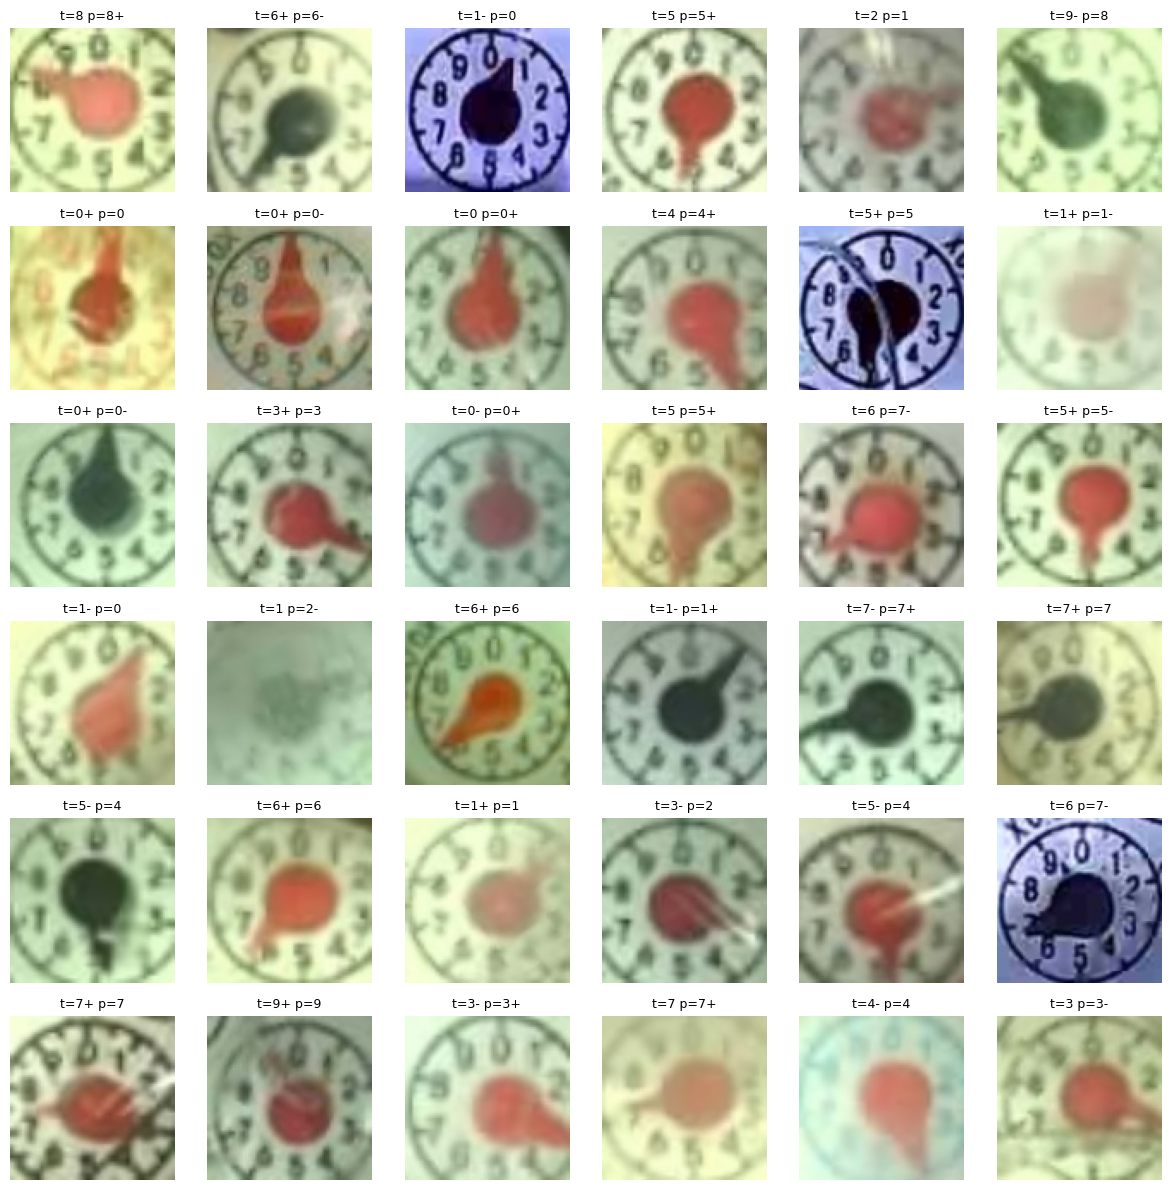

In [149]:
# Use the "chosen" method for error analysis
preds = results['EfficientNet-B0 + CA']['preds']
labels = results['EfficientNet-B0 + CA']['labels']

# Store the indexes where the prediction is wrong
wrong_idx = []

for i in range(len(labels)):
    if preds[i] != labels[i]:
        wrong_idx.append(i)

print('Misclassified test crops:', len(wrong_idx), 'of', len(labels))


# Sample a grid of misclassified images for visual inspection
random.seed(42)
sample_size = min(36, len(wrong_idx))
sample_idx = random.sample(list(wrong_idx), sample_size)

plt.figure(figsize=(12, 12))

for plot_i, dataset_i in enumerate(sample_idx):

    # Load the image directly from the saved crop path so the original
    # appearance is shown (not the normalised tensor).
    path, label_idx = test_records[dataset_i]
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    true_name = class_labels[labels[dataset_i]]
    pred_name = class_labels[preds[dataset_i]]

    plt.subplot(6, 6, plot_i + 1)
    plt.imshow(img)
    plt.title('t=' + true_name + ' p=' + pred_name, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

<p>Per-class accuracy is then plotted as a bar chart. Bars below the dashed
overall-accuracy line are the dial classes the chosen model handles worst.</p>

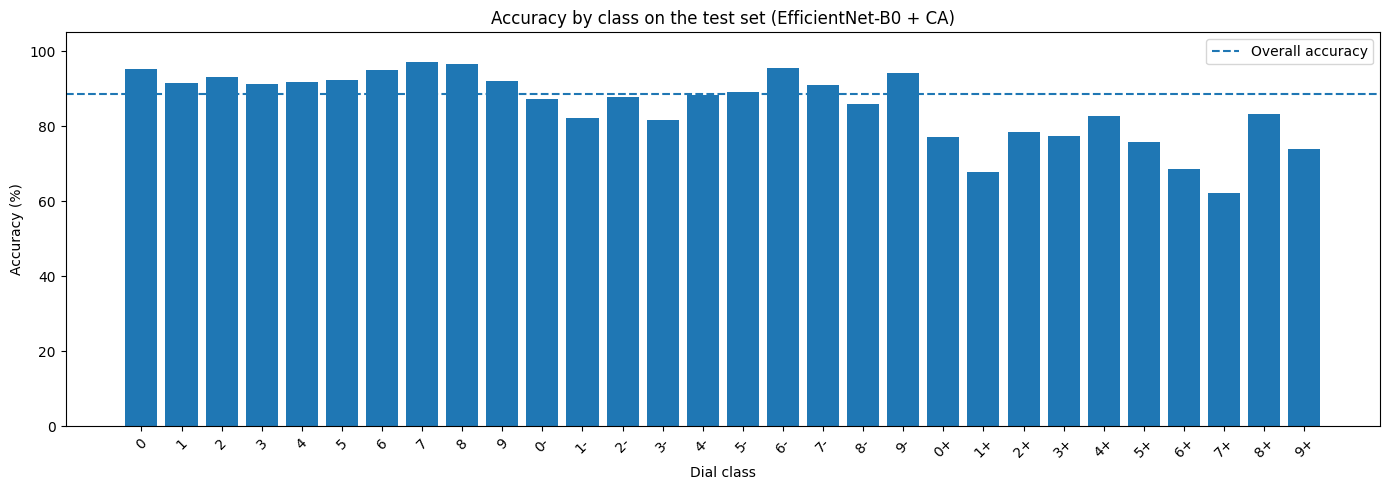

In [150]:
# Per-class accuracy for the chosen method
per_class_correct = np.zeros(num_classes)
per_class_total = np.zeros(num_classes)

# Loop through each test example and update the total 
# and correct count for its true class
for i in range(len(labels)):

    true_label = labels[i]
    predicted_label = preds[i]

    per_class_total[true_label] += 1

    if true_label == predicted_label:
        per_class_correct[true_label] += 1

# Avoid divide-by-zero for empty classes (unlikely here but safe)
per_class_acc = np.zeros(num_classes)

for i in range(num_classes):
    if per_class_total[i] > 0:
        per_class_acc[i] = per_class_correct[i] / per_class_total[i]
    else:
        per_class_acc[i] = 0.0

overall_acc = results['EfficientNet-B0 + CA']['accuracy']


plt.figure(figsize=(14, 5))
plt.bar(range(num_classes), per_class_acc * 100)
plt.axhline(overall_acc * 100, linestyle='--', label='Overall accuracy')
plt.xticks(range(num_classes), class_labels, rotation=45)
plt.xlabel('Dial class')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy by class on the test set (EfficientNet-B0 + CA)')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

In [151]:
per_class_acc * 100

array([95.34161491, 91.4893617 , 93.08176101, 91.35802469, 91.72932331,
       92.30769231, 95.09202454, 97.03703704, 96.66666667, 92.        ,
       87.23404255, 82.30088496, 87.87878788, 81.74603175, 88.23529412,
       89.05109489, 95.62043796, 91.05691057, 85.84070796, 94.05940594,
       77.01149425, 67.69230769, 78.37837838, 77.27272727, 82.75862069,
       75.64102564, 68.62745098, 62.26415094, 83.11688312, 73.80952381])